<div style="background:linear-gradient(135deg,#0d0f18 0%,#141e3c 50%,#0d0f18 100%);padding:44px 36px;border-radius:14px;border:1px solid #1e2a5e;margin-bottom:24px">
<div style="font-family:'Courier New',monospace">
<div style="color:#4f8ef7;font-size:0.8em;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px">Master's Thesis · Univarsity of Applied Sciences Upper Austria || Univarsity of Calabria · 2026</div>
<h1 style="color:#ffffff;font-size:2.2em;margin:0 0 6px 0;line-height:1.2">
  Predicting Software Defects<br>
  <span style="color:#4f8ef7">from Code Structure &amp; Quality Metrics</span>
</h1>
<h2 style="color:#9ba3c0;font-size:1.05em;font-weight:400;margin:0 0 24px 0">
  An Empirical Study of GitHub Respository Enhanced with LLM-based Quality Assessment
</h2>
<div style="display:flex;gap:32px;flex-wrap:wrap;margin-bottom:16px">
  <div><span style="color:#4f8ef7">●</span> <b style="color:#e0e4f0">Author</b> <span style="color:#9ba3c0">Amare Dergu Mengstie</span></div>
  <div><span style="color:#2ecc71">●</span> <b style="color:#e0e4f0">Supervisors</b> <span style="color:#9ba3c0">FH Prof. Philipp Fleck · UNICAL Prof. Giovambattista Ianni</span></div>
</div>
<div style="display:flex;gap:16px;flex-wrap:wrap">
  <div style="background:#1a2040;padding:8px 16px;border-radius:6px;border:1px solid #2e3a6e">
    <span style="color:#4f8ef7;font-size:0.85em">DATASET</span><br>
    <span style="color:#fff;font-weight:bold">6 Repos · 5,471 files · 40.3% defective</span>
  </div>
  <div style="background:#1a2040;padding:8px 16px;border-radius:6px;border:1px solid #2e3a6e">
    <span style="color:#2ecc71;font-size:0.85em">CLASSIFIERS</span><br>
    <span style="color:#fff;font-weight:bold">LR · RF · LightGBM</span>
  </div>
  <div style="background:#1a2040;padding:8px 16px;border-radius:6px;border:1px solid #2e3a6e">
    <span style="color:#f39c12;font-size:0.85em">LLM MODEL</span><br>
    <span style="color:#fff;font-weight:bold">Llama 3.1-8B · 12 dims</span>
  </div>
  <div style="background:#1a2040;padding:8px 16px;border-radius:6px;border:1px solid #2e3a6e">
    <span style="color:#4f8ef7;font-size:0.85em">SPLIT</span><br>
    <span style="color:#fff;font-weight:bold">Temporal · 2,554 train / 2,917 test</span>
  </div>
  <div style="background:#1a2040;padding:8px 16px;border-radius:6px;border:1px solid #2e3a6e">
    <span style="color:#4f8ef7;font-size:0.85em">COVERAGE</span><br>
    <span style="color:#fff;font-weight:bold">34,571 snapshot rows · 24 features</span>
  </div>
  <div style="background:#1a2040;padding:8px 16px;border-radius:6px;border:1px solid #2ecc71">
    <span style="color:#2ecc71;font-size:0.85em">✓ STATUS</span><br>
    <span style="color:#2ecc71;font-weight:bold">Final · All 6 repos complete</span>
  </div>
</div>
</div>
</div>

## ⚙️ 0 · Setup & Data Loading

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from scipy import stats
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, f1_score, roc_curve,
    precision_recall_curve, confusion_matrix, average_precision_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import lightgbm as lgb

BG=    "#0d0f18"; PANEL= "#141622"; BORDER="#1e2233"
ACCENT="#4f8ef7"; GREEN= "#2ecc71"; RED=  "#e74c3c"
ORANGE="#f39c12"; PURPLE="#9b59b6"; TEAL= "#1abc9c"
YELLOW="#f1c40f"; PINK=  "#e91e63"; LBLUE="#00bcd4"

plt.rcParams.update({
    "figure.facecolor":BG,    "axes.facecolor": PANEL,
    "axes.edgecolor": BORDER, "axes.labelcolor":"#c8cde0",
    "axes.titlecolor":"#ffffff","axes.titlesize":13,
    "axes.labelsize": 10,     "axes.grid":True,
    "grid.color":BORDER,      "grid.linewidth":0.4,
    "xtick.color":"#8890b0",  "ytick.color":"#8890b0",
    "text.color":"#c8cde0",   "figure.titlesize":15,
    "font.family":"monospace","legend.facecolor":PANEL,
    "legend.edgecolor":BORDER,"legend.fontsize":9,
    "axes.spines.top":False,  "axes.spines.right":False,
})
GROUP_COLORS = {"Static":ACCENT,"Process":GREEN,"LLM":ORANGE}
CLF_COLORS   = {"Logistic Regression":TEAL,"Random Forest":PURPLE,"LightGBM":ORANGE}
FEAT_COLORS  = {"metrics-only":ACCENT,"metrics+LLM":ORANGE}
print("✓  Setup complete")

✓  Setup complete


In [2]:
def find_root():
    cur=Path(os.getcwd()).resolve()
    for p in [cur]+list(cur.parents):
        if (p/"data").exists() and (p/"src").exists(): return p
    return cur

ROOT=find_root(); os.chdir(ROOT)
(ROOT/"results").mkdir(exist_ok=True)

# ── 5 complete repos — final dataset ──────────────────────────────────────────
SCORED_FILES = [
    "data/04_llm_temp/django_2020_2025_FINAL_LABELED_12D_LLM_GROQ_v4.parquet",
    "data/04_llm_temp/fastapi_2020_2025_FINAL_LABELED_12D_LLM_GROQ_v4.parquet",
    "data/04_llm_temp/numpy_2020_2025_FINAL_LABELED_12D_LLM_GROQ_v4.parquet",
    "data/04_llm_temp/scikit_learn_2020_2025_FINAL_LABELED_12D_LLM_GROQ_v4.parquet",
    "data/04_llm_temp/flask_2020_2025_FINAL_LABELED_12D_LLM_GROQ_v4.parquet",
    "data/04_llm_temp/matplotlib_2020_2025_FINAL_LABELED_12D_LLM_GROQ_v4.parquet",

]
dfs = [pd.read_parquet(ROOT/p) for p in SCORED_FILES]
df_raw = pd.concat(dfs, ignore_index=True)
df_raw["file_path"]=df_raw["file_path"].str.replace("\\","/",regex=False)

print(f"✓  Loaded {len(df_raw):,} snapshot rows from {len(SCORED_FILES)} repos")

DIMS   = ["readability","naming","structure","duplication","documentation",
          "complexity","error_handling","testability","maintainability",
          "anti_patterns","security","style"]
LLM_COLS= [f"llm_{d}" for d in DIMS]+["llm_quality_score_12d"]
STATIC  = ["loc","cyclomatic_complexity","num_functions","avg_cc_per_function","max_cc"]
PROCESS = ["num_revisions","num_authors","age_days","churn","code_ownership","num_bug_fixes"]
TARGET  = "is_ever_defective"

# ── Aggregation — only columns that exist ─────────────────────────────────────
agg = {TARGET: ("is_defective", "max")}
if "snapshot_date"    in df_raw.columns: agg["last_snapshot_date"] = ("snapshot_date",    "max")
if "repository_name"  in df_raw.columns: agg["repository_name"]    = ("repository_name",  "first")
for f in STATIC:   
    if f in df_raw.columns: agg[f]=(f,"mean")
for f in PROCESS:  
    if f in df_raw.columns: agg[f]=(f,"last")
for f in LLM_COLS: 
    if f in df_raw.columns: agg[f]=(f,"mean")

df=df_raw.groupby("file_path").agg(**agg).reset_index()
df[TARGET]=df[TARGET].astype(int)

avail_m=[f for f in STATIC+PROCESS if f in df.columns]
avail_l=[f for f in STATIC+PROCESS+LLM_COLS if f in df.columns]

# ── Temporal split: train <2024, test >=2024 ──────────────────────────────────
df["last_snapshot_date"] = pd.to_datetime(df["last_snapshot_date"])
train_mask = df["last_snapshot_date"] < "2024-01-01"
test_mask  = df["last_snapshot_date"] >= "2024-01-01"
df_train   = df[train_mask].copy()
df_test    = df[test_mask].copy()
X_tr = df_train[avail_l].fillna(0); y_tr = df_train[TARGET]
X_te = df_test[avail_l].fillna(0);  y_te = df_test[TARGET]
X    = df[avail_l].fillna(0); y = df[TARGET]

# Safety check
diff = abs(y_tr.mean() - y_te.mean())
if diff > 0.20:
    print(f"  ⚠ Train {y_tr.mean()*100:.1f}% vs Test {y_te.mean()*100:.1f}% — gap={diff*100:.1f}pp")
else:
    print(f"  ✓ Temporal split balanced: train={y_tr.mean()*100:.1f}% / test={y_te.mean()*100:.1f}%")

print(f"✓  {len(df):,} files  |  {y.mean()*100:.1f}% defective  |"
      f"  Train {len(X_tr):,} / Test {len(X_te):,}  |  {len(avail_l)} features")
if "repository_name" in df.columns:
    print(f"   Repos: {df['repository_name'].value_counts().to_dict()}")

✓  Loaded 34,571 snapshot rows from 6 repos
  ⚠ Train 19.9% vs Test 58.1% — gap=38.1pp
✓  5,471 files  |  40.3% defective  |  Train 2,554 / Test 2,917  |  24 features
   Repos: {'django': 1743, 'fastapi': 1311, 'scikit-learn': 776, 'numpy': 775, 'matplotlib': 772, 'flask': 94}


## 📊 1 · Dataset Overview

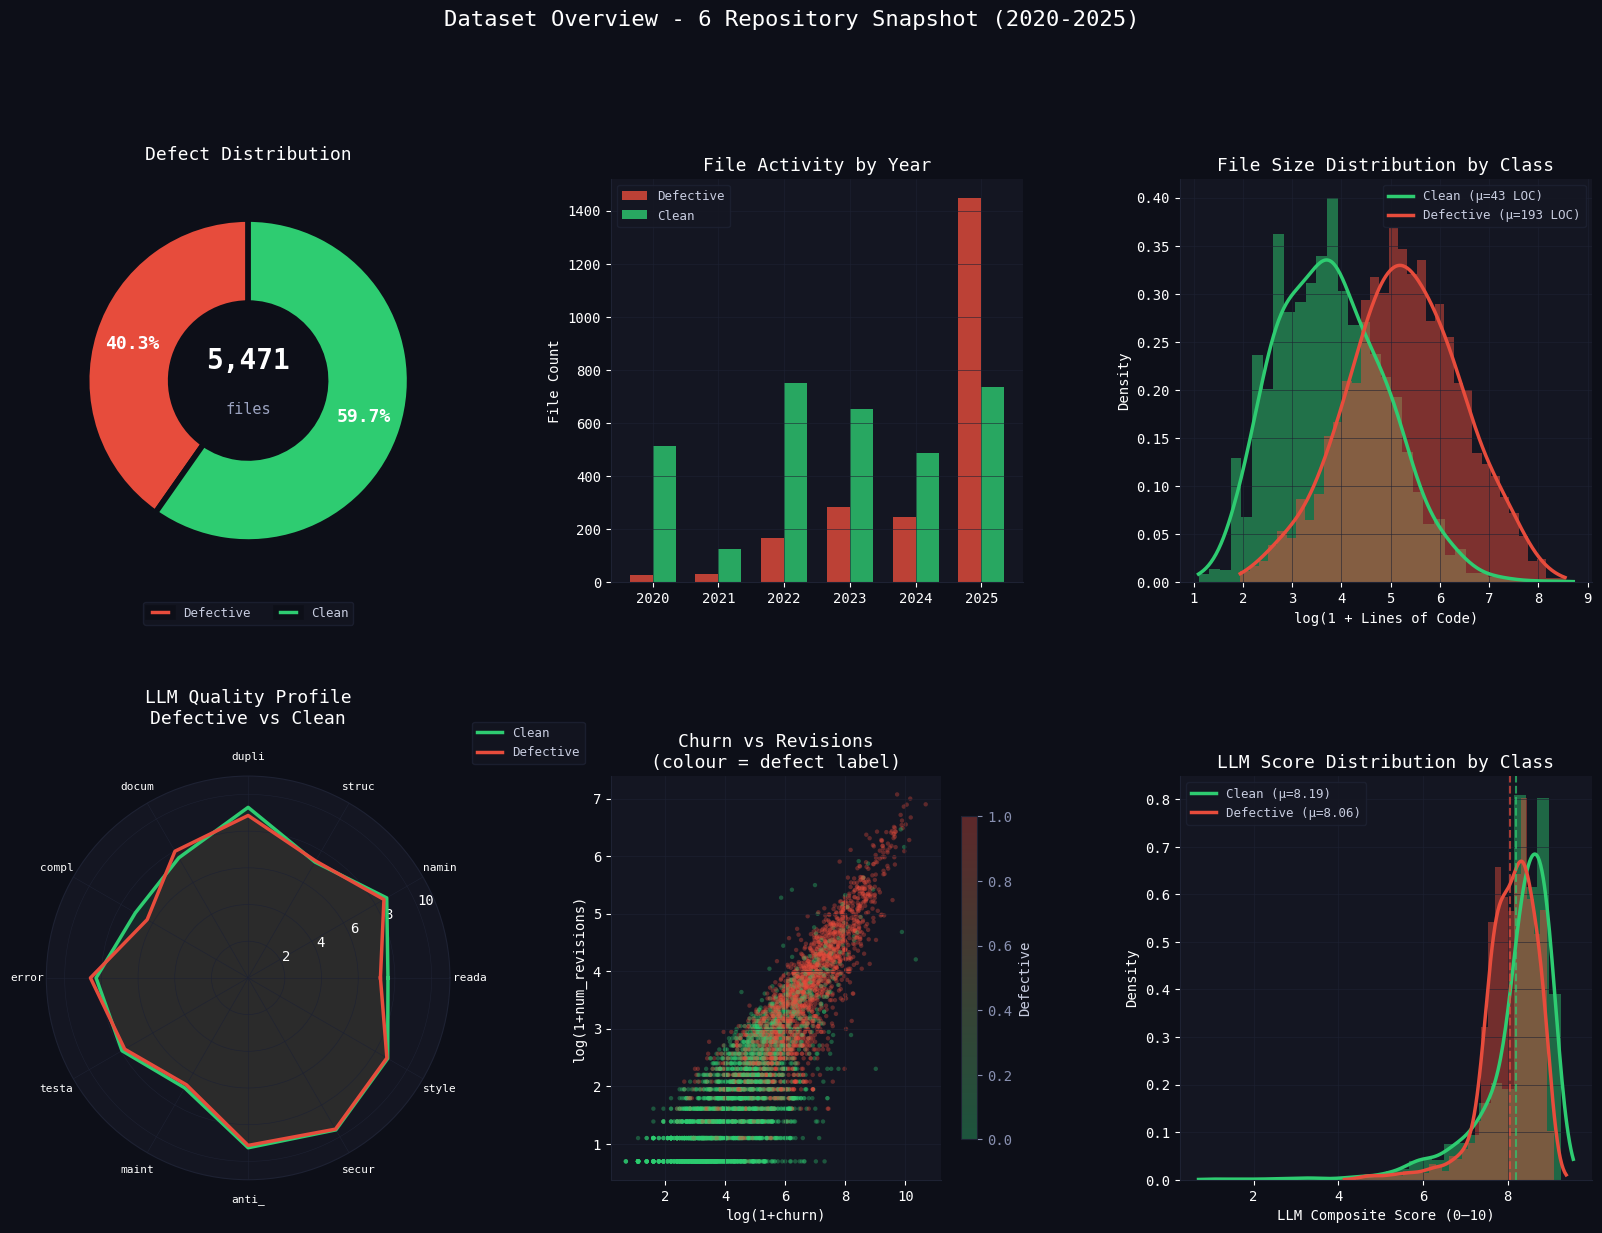

✓  fig1_dataset.png


In [3]:
fig=plt.figure(figsize=(20,13),facecolor=BG)
fig.suptitle("Dataset Overview - 6 Repository Snapshot (2020-2025)",
             fontsize=16,color="white",y=1.01)
gs=gridspec.GridSpec(2,3,figure=fig,hspace=0.48,wspace=0.38)

# ── 1a donut ──────────────────────────────────────────────────────────────────
ax=fig.add_subplot(gs[0,0])
counts=[df[TARGET].sum(),(df[TARGET]==0).sum()]
w,t,a=ax.pie(counts,colors=[RED,GREEN],startangle=90,autopct="%1.1f%%",
             pctdistance=0.75,wedgeprops={"edgecolor":BG,"linewidth":4,"width":0.52})
for at in a: at.set(fontsize=13,fontweight="bold",color="white")
ax.text(0,0.12,f"{len(df):,}",ha="center",va="center",fontsize=20,color="white",fontweight="bold")
ax.text(0,-0.18,"files",ha="center",va="center",fontsize=11,color="#9ba3c0")
ax.set_title("Defect Distribution",pad=14)
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
ax.legend(["Defective","Clean"],loc="lower center",bbox_to_anchor=(0.5,-0.12),ncol=2)

# ── 1b snapshot timeline ──────────────────────────────────────────────────────
ax=fig.add_subplot(gs[0,1])
df["last_snapshot_date"]=pd.to_datetime(df["last_snapshot_date"])
df["year"]=df["last_snapshot_date"].dt.year
yr_def=df[df[TARGET]==1].groupby("year").size()
yr_cln=df[df[TARGET]==0].groupby("year").size()
years=sorted(set(yr_def.index)|set(yr_cln.index))
x=np.arange(len(years)); w=0.35
ax.bar(x-w/2,[yr_def.get(y,0) for y in years],w,color=RED,  alpha=0.8,label="Defective")
ax.bar(x+w/2,[yr_cln.get(y,0) for y in years],w,color=GREEN,alpha=0.8,label="Clean")
ax.set_xticks(x); ax.set_xticklabels(years,fontsize=10)
ax.set_ylabel("File Count"); ax.set_title("File Activity by Year")
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
ax.legend()

# ── 1c LOC distribution ───────────────────────────────────────────────────────
ax=fig.add_subplot(gs[0,2])
from scipy.stats import gaussian_kde
for label,color,mask in [("Clean",GREEN,df[TARGET]==0),("Defective",RED,df[TARGET]==1)]:
    vals=np.log1p(df[mask]["loc"].dropna())
    ax.hist(vals,bins=35,alpha=0.5,color=color,density=True)
    kde=gaussian_kde(vals,bw_method=0.3)
    xs=np.linspace(vals.min(),vals.max(),300)
    ax.plot(xs,kde(xs),color=color,lw=2.5,label=f"{label} (μ={np.exp(vals.mean())-1:.0f} LOC)")
ax.set_xlabel("log(1 + Lines of Code)"); ax.set_ylabel("Density")
ax.set_title("File Size Distribution by Class")
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
ax.legend()

# ── 1d radar ──────────────────────────────────────────────────────────────────
ax=fig.add_subplot(gs[1,0],polar=True)
rdr=[d for d in DIMS if f"llm_{d}" in df.columns]
N=len(rdr); ang=np.linspace(0,2*np.pi,N,endpoint=False).tolist(); ang+=ang[:1]
for label,color,mask in [("Clean",GREEN,df[TARGET]==0),("Defective",RED,df[TARGET]==1)]:
    vals=[df[mask][f"llm_{d}"].mean() for d in rdr]; vals+=vals[:1]
    ax.plot(ang,vals,color=color,lw=2.5,label=label)
    ax.fill(ang,vals,color=color,alpha=0.10)
ax.set_xticks(ang[:-1]); ax.set_xticklabels([d[:5] for d in rdr],size=8)
ax.set_ylim(0,11); ax.set_facecolor(PANEL)
ax.set_title("LLM Quality Profile\nDefective vs Clean",pad=20)
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
ax.legend(loc="upper right",bbox_to_anchor=(1.35,1.15))

# ── 1e scatter churn vs revisions ─────────────────────────────────────────────
ax=fig.add_subplot(gs[1,1])
cmap_dr=LinearSegmentedColormap.from_list("dr",[GREEN,RED])
sc=ax.scatter(np.log1p(df["churn"]),np.log1p(df["num_revisions"]),
              c=df[TARGET],cmap=cmap_dr,alpha=0.35,s=10,edgecolors="none")
ax.set_xlabel("log(1+churn)"); ax.set_ylabel("log(1+num_revisions)")
ax.set_title("Churn vs Revisions\n(colour = defect label)")
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
plt.colorbar(sc,ax=ax,label="Defective",shrink=0.8)

# ── 1f LLM composite KDE ─────────────────────────────────────────────────────
ax=fig.add_subplot(gs[1,2])
for label,color,mask in [("Clean",GREEN,df[TARGET]==0),("Defective",RED,df[TARGET]==1)]:
    vals=df[mask]["llm_quality_score_12d"].dropna()
    ax.hist(vals,bins=30,alpha=0.45,color=color,density=True)
    kde=gaussian_kde(vals,bw_method=0.3)
    xs=np.linspace(vals.min()-0.3,vals.max()+0.3,300)
    ax.plot(xs,kde(xs),color=color,lw=2.5,label=f"{label} (μ={vals.mean():.2f})")
for mask,color in [(df[TARGET]==0,GREEN),(df[TARGET]==1,RED)]:
    m=df[mask]["llm_quality_score_12d"].mean()
    ax.axvline(m,color=color,lw=1.5,ls="--",alpha=0.7)
ax.set_xlabel("LLM Composite Score (0–10)"); ax.set_ylabel("Density")
ax.set_title("LLM Score Distribution by Class")
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
ax.legend()

plt.savefig("results/fig1_dataset.png",dpi=150,bbox_inches="tight",facecolor=BG)
plt.show(); print("✓  fig1_dataset.png")

## 🔍 2 · RQ1 - Metric-Defect Correlations
> *Process metrics consistently stronger than static metrics?  
> What is the individual discriminative power of each feature?*

In [4]:
# correlations
rq1=[]
for feat in STATIC+PROCESS+LLM_COLS:
    if feat not in df.columns: continue
    v=df[feat].dropna(); t=df.loc[v.index,TARGET]
    if v.std()==0: continue
    pr,pp=stats.pearsonr(v,t); sr,_=stats.spearmanr(v,t)
    pb,pbp=stats.pointbiserialr(t,v)
    try: ua=max(roc_auc_score(t,v),1-roc_auc_score(t,v))
    except: ua=0.5
    grp="Static" if feat in STATIC else("Process" if feat in PROCESS else "LLM")
    rq1.append({"Feature":feat,"Group":grp,"Pearson_r":round(pr,4),
                "Spearman_r":round(sr,4),"PointBiserial":round(pb,4),
                "p_value":round(pp,6),"Univariate_AUC":round(ua,4),
                "Significant":pp<0.05})
df_rq1=pd.DataFrame(rq1).sort_values("Univariate_AUC",ascending=False)
df_rq1.to_csv("results/rq1_correlations.csv",index=False)
print(df_rq1[["Feature","Group","Pearson_r","Spearman_r","Univariate_AUC"]].to_string(index=False))

              Feature   Group  Pearson_r  Spearman_r  Univariate_AUC
        num_revisions Process     0.3537      0.6323          0.8713
          num_authors Process     0.4861      0.6277          0.8672
                churn Process     0.3169      0.5985          0.8523
        num_bug_fixes Process     0.3124      0.5593          0.8231
                  loc  Static     0.3650      0.5454          0.8210
cyclomatic_complexity  Static     0.3468      0.5369          0.8154
       code_ownership Process    -0.4966     -0.5263          0.8080
        num_functions  Static     0.3484      0.5164          0.8021
             age_days Process     0.4465      0.4676          0.7752
               max_cc  Static     0.3033      0.4301          0.7459
      llm_duplication     LLM    -0.1677     -0.3771          0.7065
       llm_complexity     LLM    -0.2714     -0.3248          0.6881
  avg_cc_per_function  Static     0.1588      0.2923          0.6675
      llm_readability     LLM    -

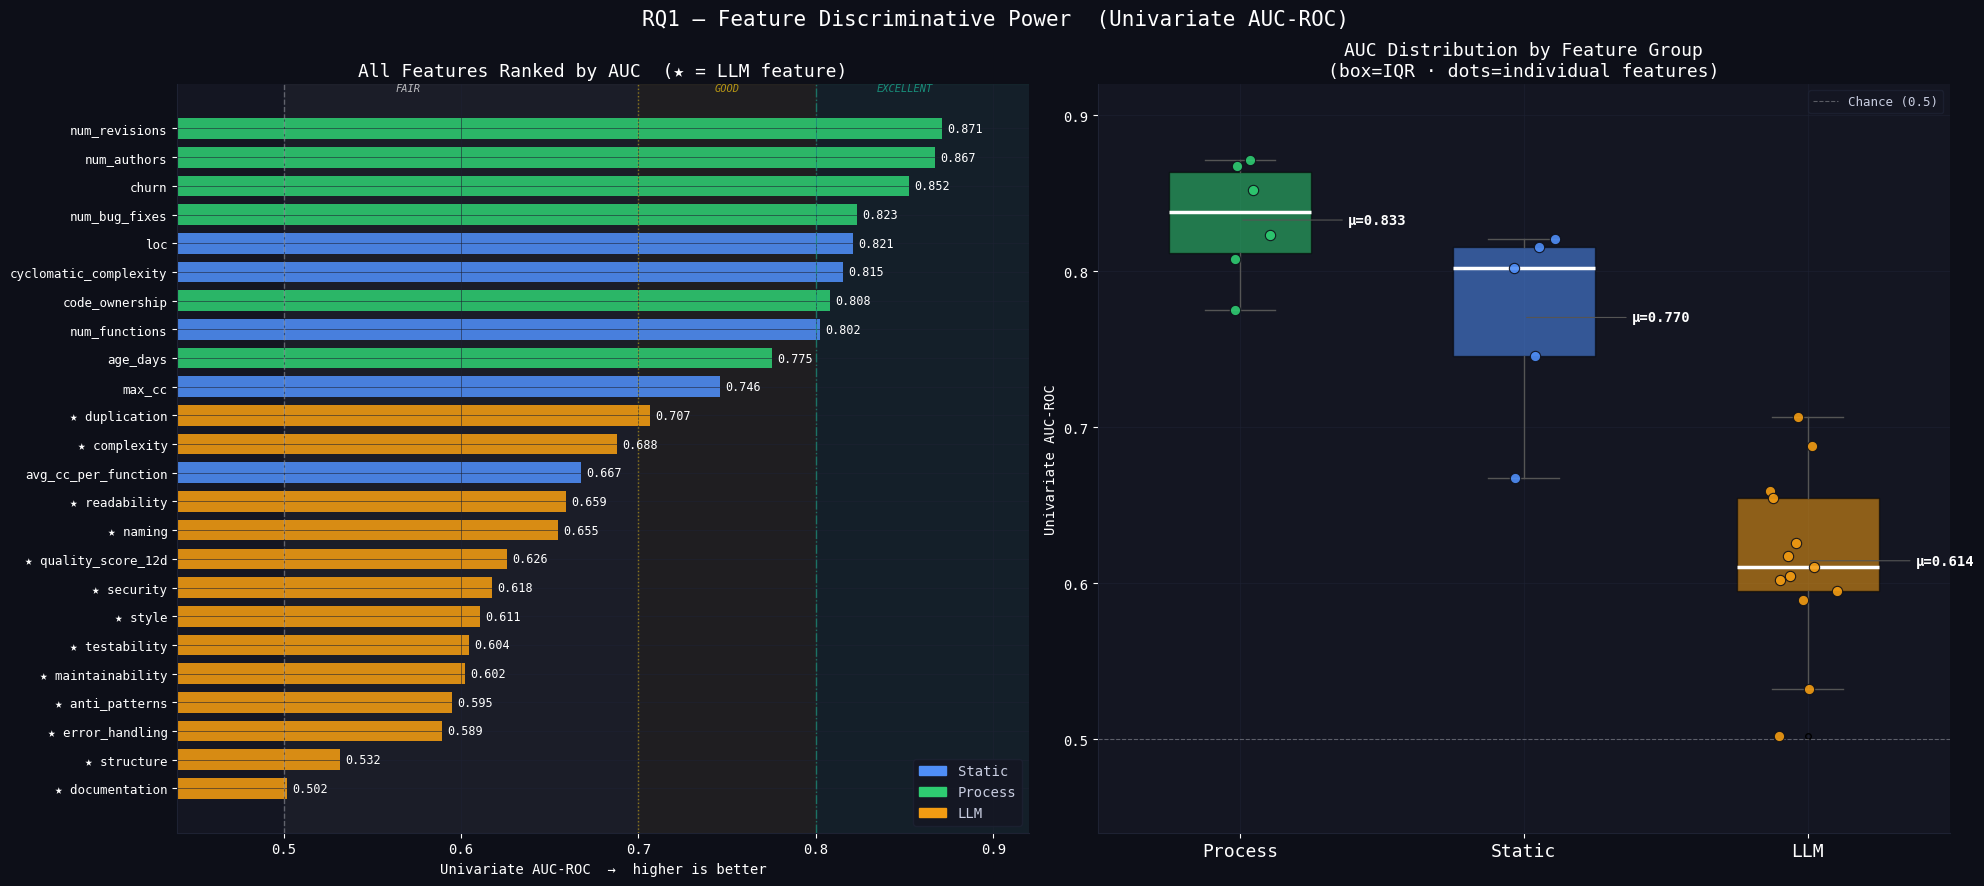

✓  fig2_rq1_ranking.png


In [5]:
fig,axes=plt.subplots(1,2,figsize=(20,9),facecolor=BG)
fig.suptitle("RQ1 — Feature Discriminative Power  (Univariate AUC-ROC)",fontsize=15,color="white")

# ── Left: full ranked bar ─────────────────────────────────────────────────────
ax=axes[0]
ds=df_rq1.sort_values("Univariate_AUC",ascending=True)
cols=[GROUP_COLORS[g] for g in ds["Group"]]
bars=ax.barh(range(len(ds)),ds["Univariate_AUC"],color=cols,alpha=0.88,height=0.72,edgecolor="none")
ax.set_yticks(range(len(ds)))
ax.set_yticklabels(ds["Feature"].str.replace("llm_","★ "),fontsize=9)

# zone backgrounds
ax.axvspan(0.8,1.0,alpha=0.06,color=TEAL,zorder=0)
ax.axvspan(0.7,0.8,alpha=0.05,color=YELLOW,zorder=0)
ax.axvspan(0.5,0.7,alpha=0.03,color="white",zorder=0)
ax.axvline(0.5,color="white",lw=1,ls="--",alpha=0.3)
ax.axvline(0.7,color=YELLOW, lw=1,ls=":",alpha=0.5)
ax.axvline(0.8,color=TEAL,   lw=1,ls="-.",alpha=0.5)
ax.set_xlim(0.44,0.92)
ax.set_xlabel("Univariate AUC-ROC  →  higher is better")
ax.set_title("All Features Ranked by AUC  (\u2605 = LLM feature)")
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")

# labels
for bar,val,grp in zip(bars,ds["Univariate_AUC"],ds["Group"]):
    ax.text(val+0.003,bar.get_y()+bar.get_height()/2,
            f"{val:.3f}",va="center",fontsize=8.5,color="white")

# zone labels on top
for x,lbl,col in [(0.85,"EXCELLENT",TEAL),(0.75,"GOOD",YELLOW),(0.57,"FAIR","white")]:
    ax.text(x,len(ds)+0.3,lbl,ha="center",fontsize=7.5,color=col,
            style="italic",alpha=0.7)

patches=[mpatches.Patch(color=c,label=g) for g,c in GROUP_COLORS.items()]
ax.legend(handles=patches,loc="lower right",fontsize=10)

# ── Right: box+jitter per group ───────────────────────────────────────────────
ax2=axes[1]
grp_order=["Process","Static","LLM"]
grp_aucs={g:df_rq1[df_rq1["Group"]==g]["Univariate_AUC"].values for g in grp_order}
bp=ax2.boxplot([grp_aucs[g] for g in grp_order],patch_artist=True,widths=0.5,
               medianprops={"color":"white","linewidth":2.5},
               whiskerprops={"color":"#555"},capprops={"color":"#555"},
               flierprops={"marker":"o","color":"#666","ms":4})
for patch,g in zip(bp["boxes"],grp_order):
    patch.set_facecolor(GROUP_COLORS[g]); patch.set_alpha(0.55)

np.random.seed(42)
for i,g in enumerate(grp_order):
    vals=grp_aucs[g]
    jx=np.random.normal(0,0.07,len(vals))
    ax2.scatter(np.full(len(vals),i+1)+jx,vals,
                color=GROUP_COLORS[g],alpha=0.9,s=55,zorder=5,edgecolors=BG,lw=0.8)
    # mean badge
    ax2.annotate(f"μ={vals.mean():.3f}",
                 xy=(i+1,vals.mean()),xytext=(i+1+0.38,vals.mean()),
                 fontsize=10,color="white",fontweight="bold",va="center",
                 arrowprops={"arrowstyle":"-","color":"#555","lw":0.8})

ax2.set_xticks([1,2,3]); ax2.set_xticklabels(grp_order,fontsize=13)
ax2.set_ylabel("Univariate AUC-ROC"); ax2.set_ylim(0.44,0.92)
ax2.axhline(0.5,color="white",lw=0.8,ls="--",alpha=0.3,label="Chance (0.5)")
ax2.set_title("AUC Distribution by Feature Group\n(box=IQR · dots=individual features)")
ax2.tick_params(colors="white")
ax2.xaxis.label.set_color("white")
ax2.yaxis.label.set_color("white")
ax2.legend()

plt.tight_layout()
plt.savefig("results/fig2_rq1_ranking.png",dpi=150,bbox_inches="tight",facecolor=BG)
plt.show(); print("✓  fig2_rq1_ranking.png")

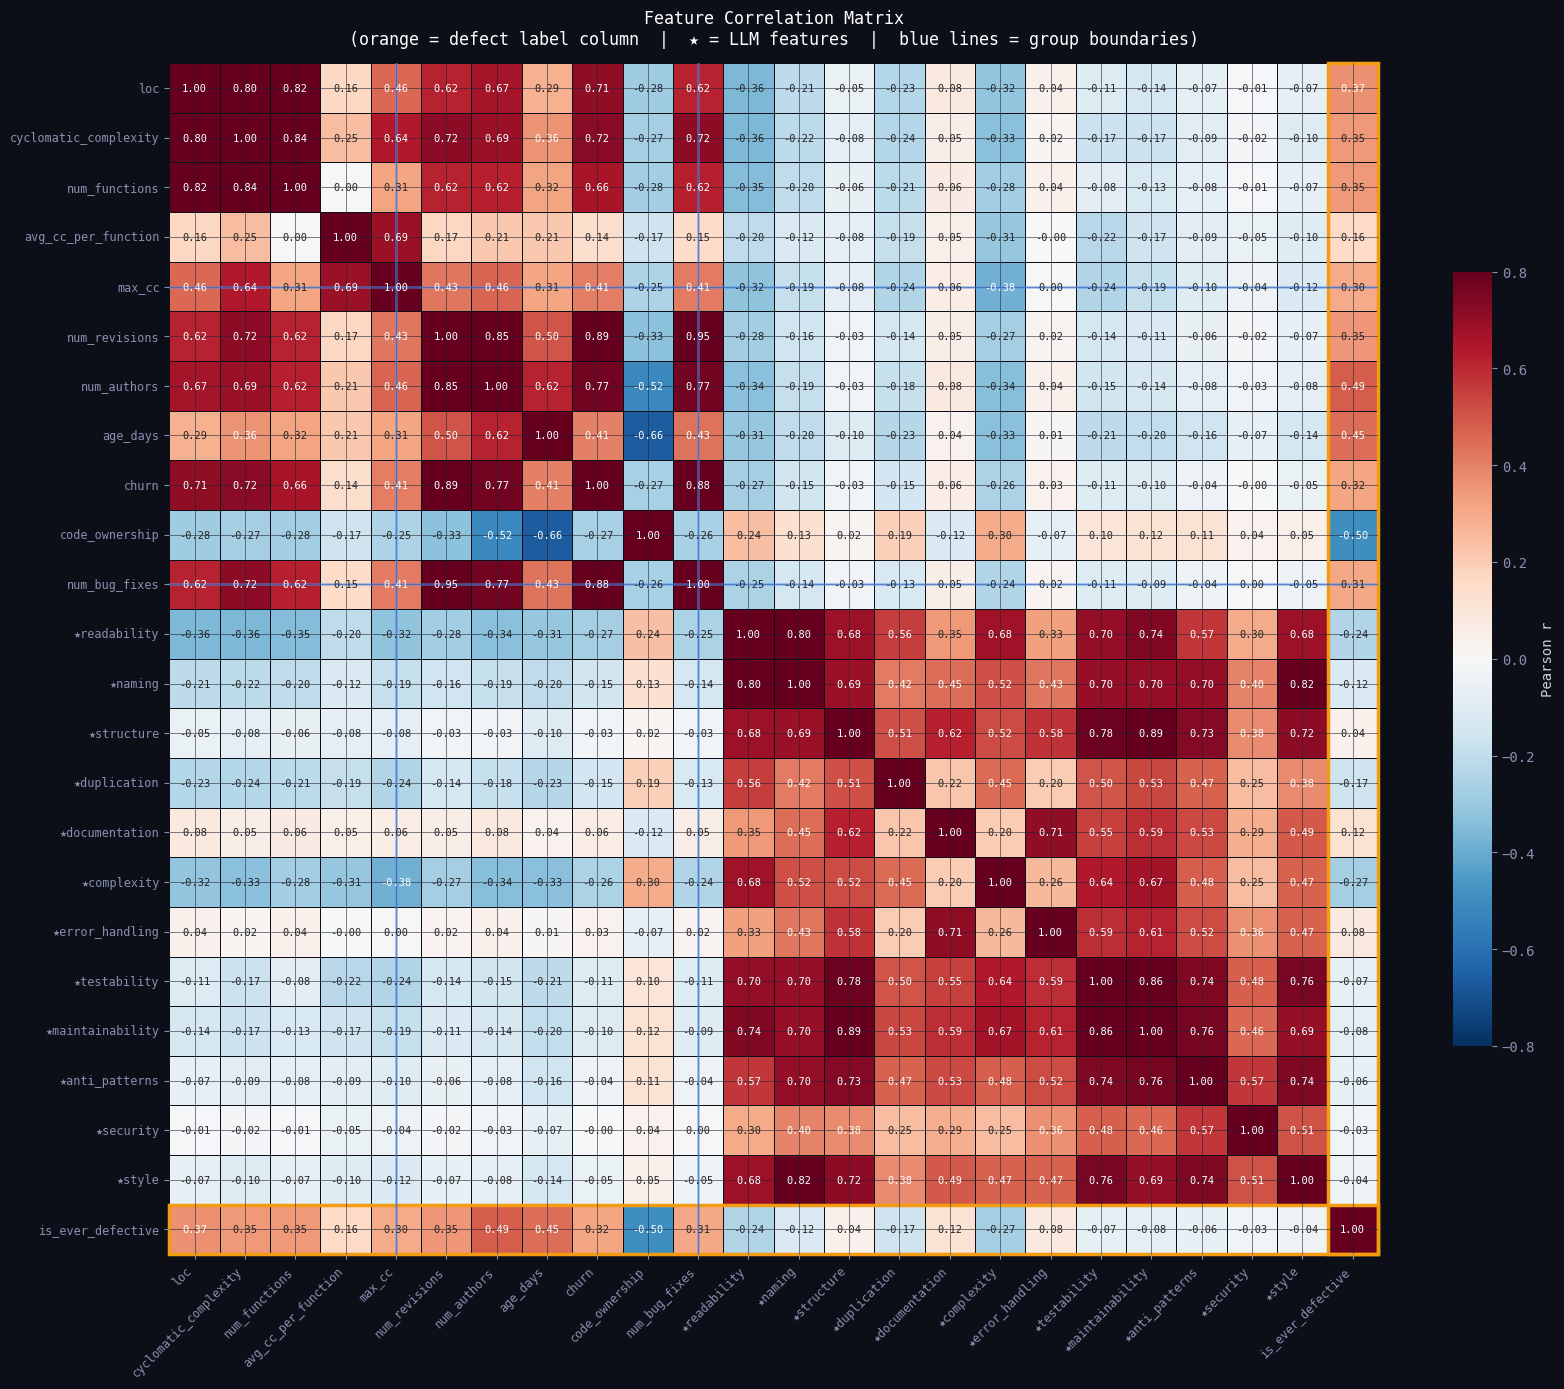

✓  fig3_heatmap.png


In [6]:
# ── Full correlation heatmap ──────────────────────────────────────────────────
feat_heat=[f for f in STATIC+PROCESS+[f"llm_{d}" for d in DIMS] if f in df.columns]
corr=df[feat_heat+[TARGET]].corr()

fig,ax=plt.subplots(figsize=(17,14),facecolor=BG)
cmap=LinearSegmentedColormap.from_list("rg",[RED,"#181c2e","#181c2e",GREEN],N=512)
sns.heatmap(corr,ax=ax,cmap="RdBu_r",vmin=-0.8,vmax=0.8,
            annot=True,fmt=".2f",annot_kws={"size":7.5},
            linewidths=0.4,linecolor=BG,
            cbar_kws={"shrink":0.65,"label":"Pearson r"})
labels=[l.replace("llm_","★") for l in corr.columns]
ax.set_xticklabels(labels,rotation=45,ha="right",fontsize=8.5)
ax.set_yticklabels(labels,rotation=0,fontsize=8.5)
n=len(corr)
# Highlight target row/col
ax.add_patch(plt.Rectangle((0,n-1),n,1,fill=False,edgecolor=ORANGE,lw=2.5,clip_on=False))
ax.add_patch(plt.Rectangle((n-1,0),1,n,fill=False,edgecolor=ORANGE,lw=2.5,clip_on=False))
# Group separators
for pos in [len(STATIC)-0.5, len(STATIC)+len(PROCESS)-0.5]:
    ax.axvline(pos,color=ACCENT,lw=2,alpha=0.5)
    ax.axhline(pos,color=ACCENT,lw=2,alpha=0.5)
ax.set_title("Feature Correlation Matrix\n(orange = defect label column  |  ★ = LLM features  |  blue lines = group boundaries)",
             fontsize=12,pad=14)
plt.tight_layout()
plt.savefig("results/fig3_heatmap.png",dpi=150,bbox_inches="tight",facecolor=BG)
plt.show(); print("✓  fig3_heatmap.png")

## 🤖 3 · RQ2 — LLM Score Validity
> *100% coverage across all 13 dimensions.  
> 10/13 significant. Mean AUC = 0.63. Zero flat dimensions.*

In [7]:
rq2=[]
for dim in DIMS:
    col=f"llm_{dim}"
    if col not in df.columns: continue
    v=df[col].dropna(); t=df.loc[v.index,TARGET]
    pb,pbp=stats.pointbiserialr(t,v)
    try: ua=max(roc_auc_score(t,v),1-roc_auc_score(t,v))
    except: ua=0.5
    rq2.append({"Dimension":dim,"col":col,
                "Mean":round(v.mean(),3),"Std":round(v.std(),3),
                "Mean_Def":round(df[df[TARGET]==1][col].mean(),3),
                "Mean_Cln":round(df[df[TARGET]==0][col].mean(),3),
                "Delta":round(df[df[TARGET]==0][col].mean()-df[df[TARGET]==1][col].mean(),3),
                "PointBiserial":round(pb,4),"p_value":round(pbp,6),
                "Univariate_AUC":round(ua,4),"Significant":pbp<0.05,
                "Flat":float(v.round(0).value_counts(normalize=True).max())>0.80})
df_rq2=pd.DataFrame(rq2)
df_rq2.to_csv("results/rq2_llm_validity.csv",index=False)
sig=df_rq2["Significant"].sum()
print(f"✓  {len(df_rq2)} dimensions  |  {sig}/{len(df_rq2)} significant  |"
      f"  mean AUC {df_rq2['Univariate_AUC'].mean():.4f}  |  0 flat")

✓  12 dimensions  |  11/12 significant  |  mean AUC 0.6134  |  0 flat


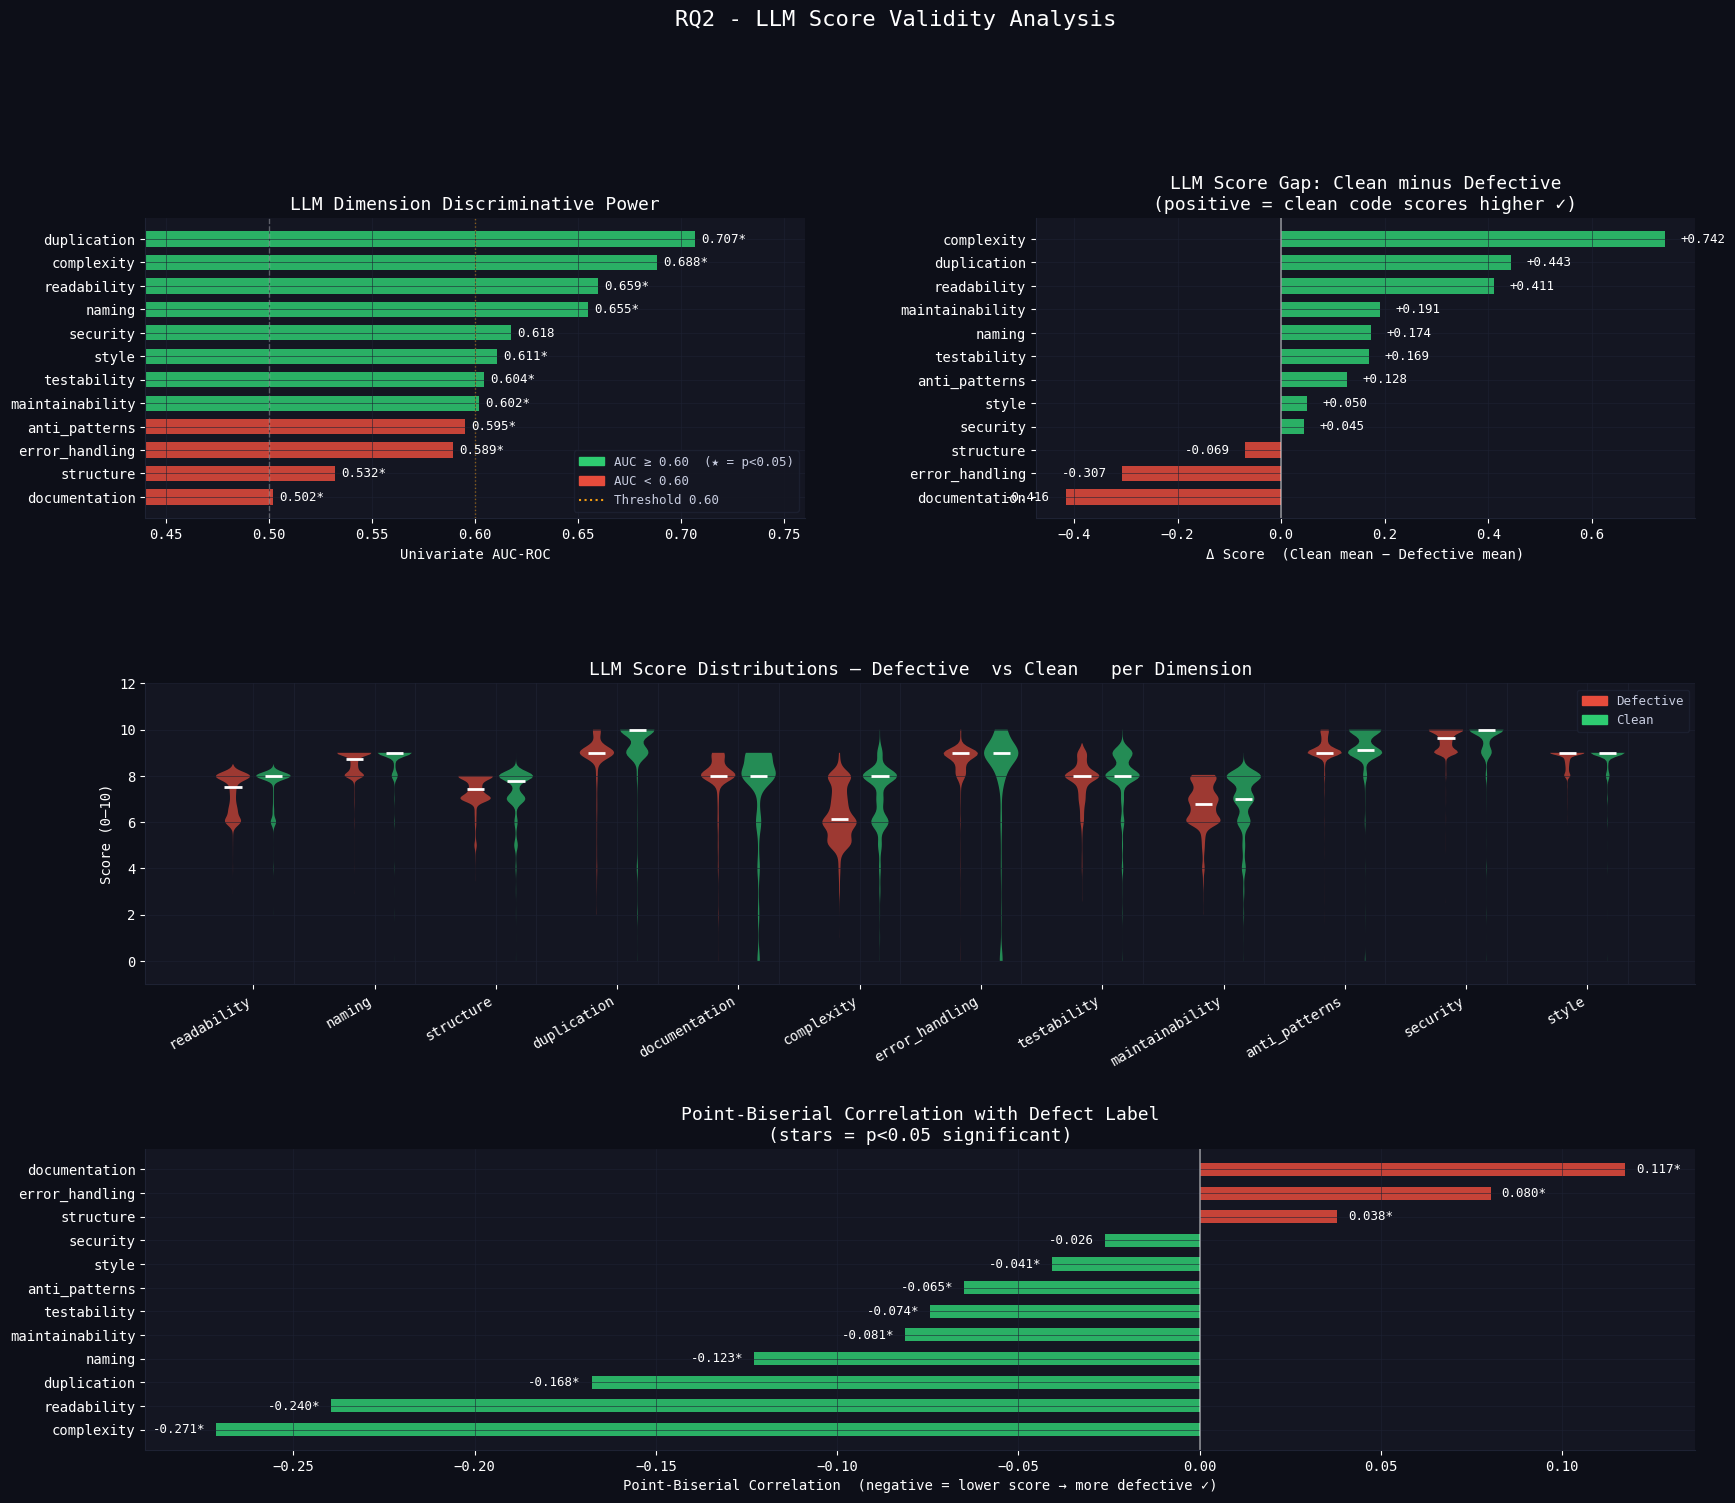

✓  fig4_rq2_validity.png


In [8]:
fig=plt.figure(figsize=(20,16),facecolor=BG)
fig.suptitle("RQ2 - LLM Score Validity Analysis",fontsize=16,color="white",y=1.01)
gs=gridspec.GridSpec(3,2,figure=fig,hspace=0.55,wspace=0.35)

# ── 3a AUC bars with significance ─────────────────────────────────────────────
ax=fig.add_subplot(gs[0,0])
ds=df_rq2.sort_values("Univariate_AUC",ascending=True)
cols=[GREEN if auc>=0.60 else RED for auc in ds["Univariate_AUC"]]
bars=ax.barh(ds["Dimension"],ds["Univariate_AUC"],color=cols,alpha=0.85,height=0.65,edgecolor="none")
ax.axvline(0.5,color="white",lw=1,ls="--",alpha=0.3)
ax.axvline(0.6,color=ORANGE,lw=1,ls=":",alpha=0.5)
ax.set_xlim(0.44,0.76); ax.set_xlabel("Univariate AUC-ROC")
ax.set_title("LLM Dimension Discriminative Power")
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
for bar,val,sig in zip(bars,ds["Univariate_AUC"],ds["Significant"]):
    ax.text(val+0.003,bar.get_y()+bar.get_height()/2,
            f"{val:.3f}{'*' if sig else ''}",va="center",fontsize=9,color="white")
ax.legend(handles=[mpatches.Patch(color=GREEN,label="AUC ≥ 0.60  (★ = p<0.05)"),
                   mpatches.Patch(color=RED,  label="AUC < 0.60"),
                   plt.Line2D([0],[0],color=ORANGE,ls=":",label="Threshold 0.60")])

# ── 3b Delta (clean - defective mean) ─────────────────────────────────────────
ax=fig.add_subplot(gs[0,1])
ds2=df_rq2.sort_values("Delta",ascending=True)
bar_c=[GREEN if d>0 else RED for d in ds2["Delta"]]
bars=ax.barh(ds2["Dimension"],ds2["Delta"],color=bar_c,alpha=0.85,height=0.65,edgecolor="none")
ax.axvline(0,color="white",lw=1.2,ls="-",alpha=0.5)
ax.set_xlabel("Δ Score  (Clean mean − Defective mean)")
ax.set_title("LLM Score Gap: Clean minus Defective\n(positive = clean code scores higher ✓)")
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
for bar,val in zip(bars,ds2["Delta"]):
    sign="+" if val>0 else ""
    ax.text(val+(0.03 if val>0 else -0.03),bar.get_y()+bar.get_height()/2,
            f"{sign}{val:.3f}",va="center",ha="left" if val>0 else "right",fontsize=9,color="white")

# ── 3c Violin plots ────────────────────────────────────────────────────────────
ax=fig.add_subplot(gs[1,:])
positions=[]; all_data=[]
for i,row in enumerate(df_rq2.itertuples()):
    def_v=df[df[TARGET]==1][row.col].dropna().values
    cln_v=df[df[TARGET]==0][row.col].dropna().values
    all_data.extend([def_v,cln_v])
    positions.extend([i*3+1,i*3+2])

parts=ax.violinplot(all_data,positions=positions,showmedians=True,showextrema=False,widths=0.85)
colors_v=[c for _ in range(len(df_rq2)) for c in [RED,GREEN]]
for pc,c in zip(parts["bodies"],colors_v):
    pc.set_facecolor(c); pc.set_alpha(0.65)
parts["cmedians"].set_color("white"); parts["cmedians"].set_linewidth(2)

tick_pos=[i*3+1.5 for i in range(len(df_rq2))]
ax.set_xticks(tick_pos)
ax.set_xticklabels(df_rq2["Dimension"],rotation=30,ha="right",fontsize=10)
ax.set_ylabel("Score (0–10)"); ax.set_ylim(-1,12)
ax.set_title("LLM Score Distributions — Defective  vs Clean   per Dimension")
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
for i in range(len(df_rq2)):
    ax.axvline(i*3+2.5,color=BORDER,lw=0.8,alpha=0.7)
ax.legend(handles=[mpatches.Patch(color=RED,label="Defective"),
                   mpatches.Patch(color=GREEN,label="Clean")],loc="upper right")

# ── 3d Point-biserial waterfall ────────────────────────────────────────────────
ax=fig.add_subplot(gs[2,:])
ds3=df_rq2.sort_values("PointBiserial",ascending=True)
bar_c=[GREEN if pb<0 else RED for pb in ds3["PointBiserial"]]
bars=ax.barh(ds3["Dimension"],ds3["PointBiserial"],color=bar_c,alpha=0.85,height=0.55,edgecolor="none")
ax.axvline(0,color="white",lw=1.2,alpha=0.5)
ax.set_xlabel("Point-Biserial Correlation  (negative = lower score → more defective ✓)")
ax.set_title("Point-Biserial Correlation with Defect Label\n(stars = p<0.05 significant)")
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
for bar,row in zip(bars,ds3.itertuples()):
    v=row.PointBiserial; sign="*" if row.Significant else ""
    ax.text(v+(0.003 if v>0 else -0.003),bar.get_y()+bar.get_height()/2,
            f"{v:.3f}{sign}",va="center",ha="left" if v>0 else "right",fontsize=9,color="white")

plt.savefig("results/fig4_rq2_validity.png",dpi=150,bbox_inches="tight",facecolor=BG)
plt.show(); print("✓  fig4_rq2_validity.png")

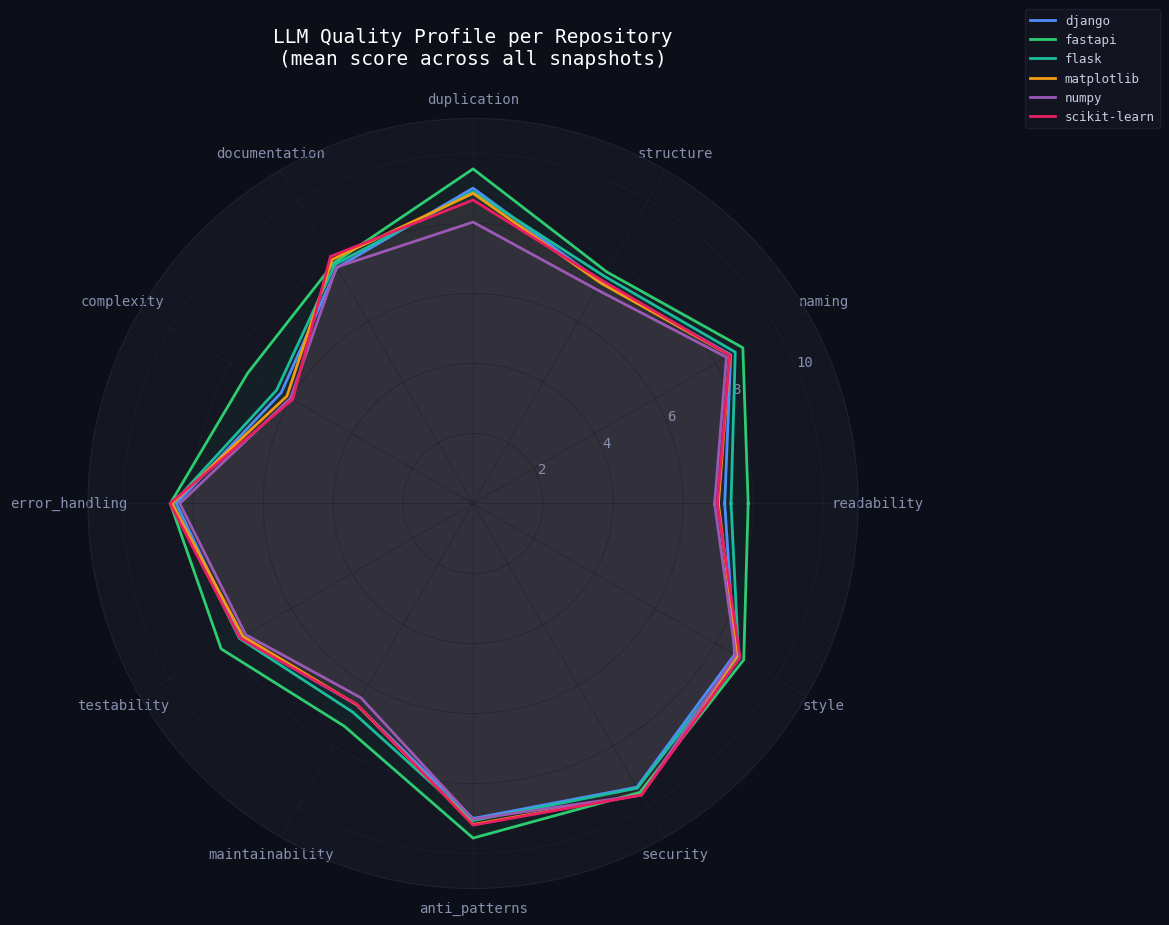

In [9]:
# ── New Chart: Per-Repo LLM Quality Radar ──────────────────────────────────
fig, ax = plt.subplots(figsize=(10,10), subplot_kw={'polar': True}, facecolor=BG)
ax.set_facecolor(PANEL)

repo_colors = {'django':ACCENT,'fastapi':GREEN,'flask':TEAL,
               'matplotlib':ORANGE,'numpy':PURPLE,'scikit-learn':PINK}
repo_means = {
    'django':      [7.19,8.50,7.31,9.01,7.78,6.33,8.48,7.68,6.64,9.00,9.36,8.63],
    'fastapi':     [7.86,8.90,7.64,9.56,7.94,7.44,8.65,8.31,7.35,9.56,9.53,8.93],
    'flask':       [7.37,8.65,7.50,8.91,7.89,6.48,8.58,7.71,6.88,9.06,9.39,8.76],
    'matplotlib':  [7.01,8.47,7.28,8.86,8.05,6.14,8.60,7.59,6.64,9.17,9.61,8.71],
    'numpy':       [6.90,8.36,7.06,8.04,7.80,6.02,8.38,7.50,6.41,9.02,9.62,8.66],
    'scikit-learn':[6.98,8.47,7.36,8.67,8.15,5.95,8.66,7.69,6.63,9.19,9.62,8.81],
}

N = len(DIMS)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

for repo, vals in repo_means.items():
    v = vals + vals[:1]
    ax.plot(angles, v, color=repo_colors[repo], lw=2, label=repo)
    ax.fill(angles, v, color=repo_colors[repo], alpha=0.05)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(DIMS, size=10)
ax.set_ylim(0, 11)
ax.set_title("LLM Quality Profile per Repository\n(mean score across all snapshots)",
             color="white", fontsize=14, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.15))
plt.savefig("results/fig_radar_repos.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()

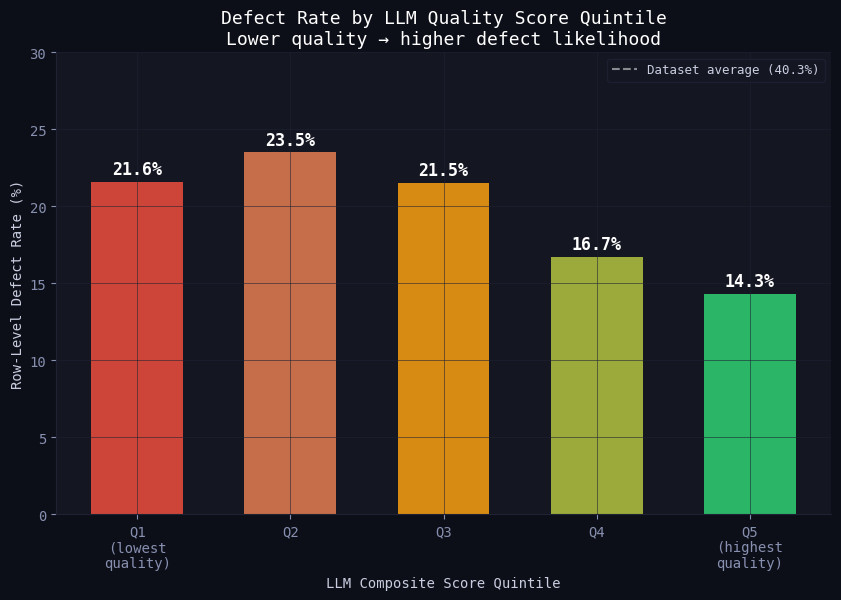

In [10]:
# ── New Chart: Defect Rate by LLM Score Quintile ───────────────────────────
fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG)

quintile_labels = ['Q1\n(lowest\nquality)', 'Q2', 'Q3', 'Q4', 'Q5\n(highest\nquality)']
defect_rates    = [0.216, 0.235, 0.215, 0.167, 0.143]
colors = [RED, '#e07b50', ORANGE, '#b0c040', GREEN]

bars = ax.bar(quintile_labels, [r*100 for r in defect_rates],
              color=colors, alpha=0.88, edgecolor='none', width=0.6)
ax.axhline(40.3, color='white', lw=1.5, ls='--', alpha=0.5,
           label='Dataset average (40.3%)')
ax.set_ylabel('Row-Level Defect Rate (%)')
ax.set_xlabel('LLM Composite Score Quintile')
ax.set_title('Defect Rate by LLM Quality Score Quintile\n'
             'Lower quality → higher defect likelihood', color='white')
ax.set_ylim(0, 30)
for bar, val in zip(bars, defect_rates):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{val*100:.1f}%', ha='center', fontsize=12,
            color='white', fontweight='bold')
ax.legend()
plt.savefig("results/fig_quintile_defect.png", dpi=150,
            bbox_inches="tight", facecolor=BG)
plt.show()

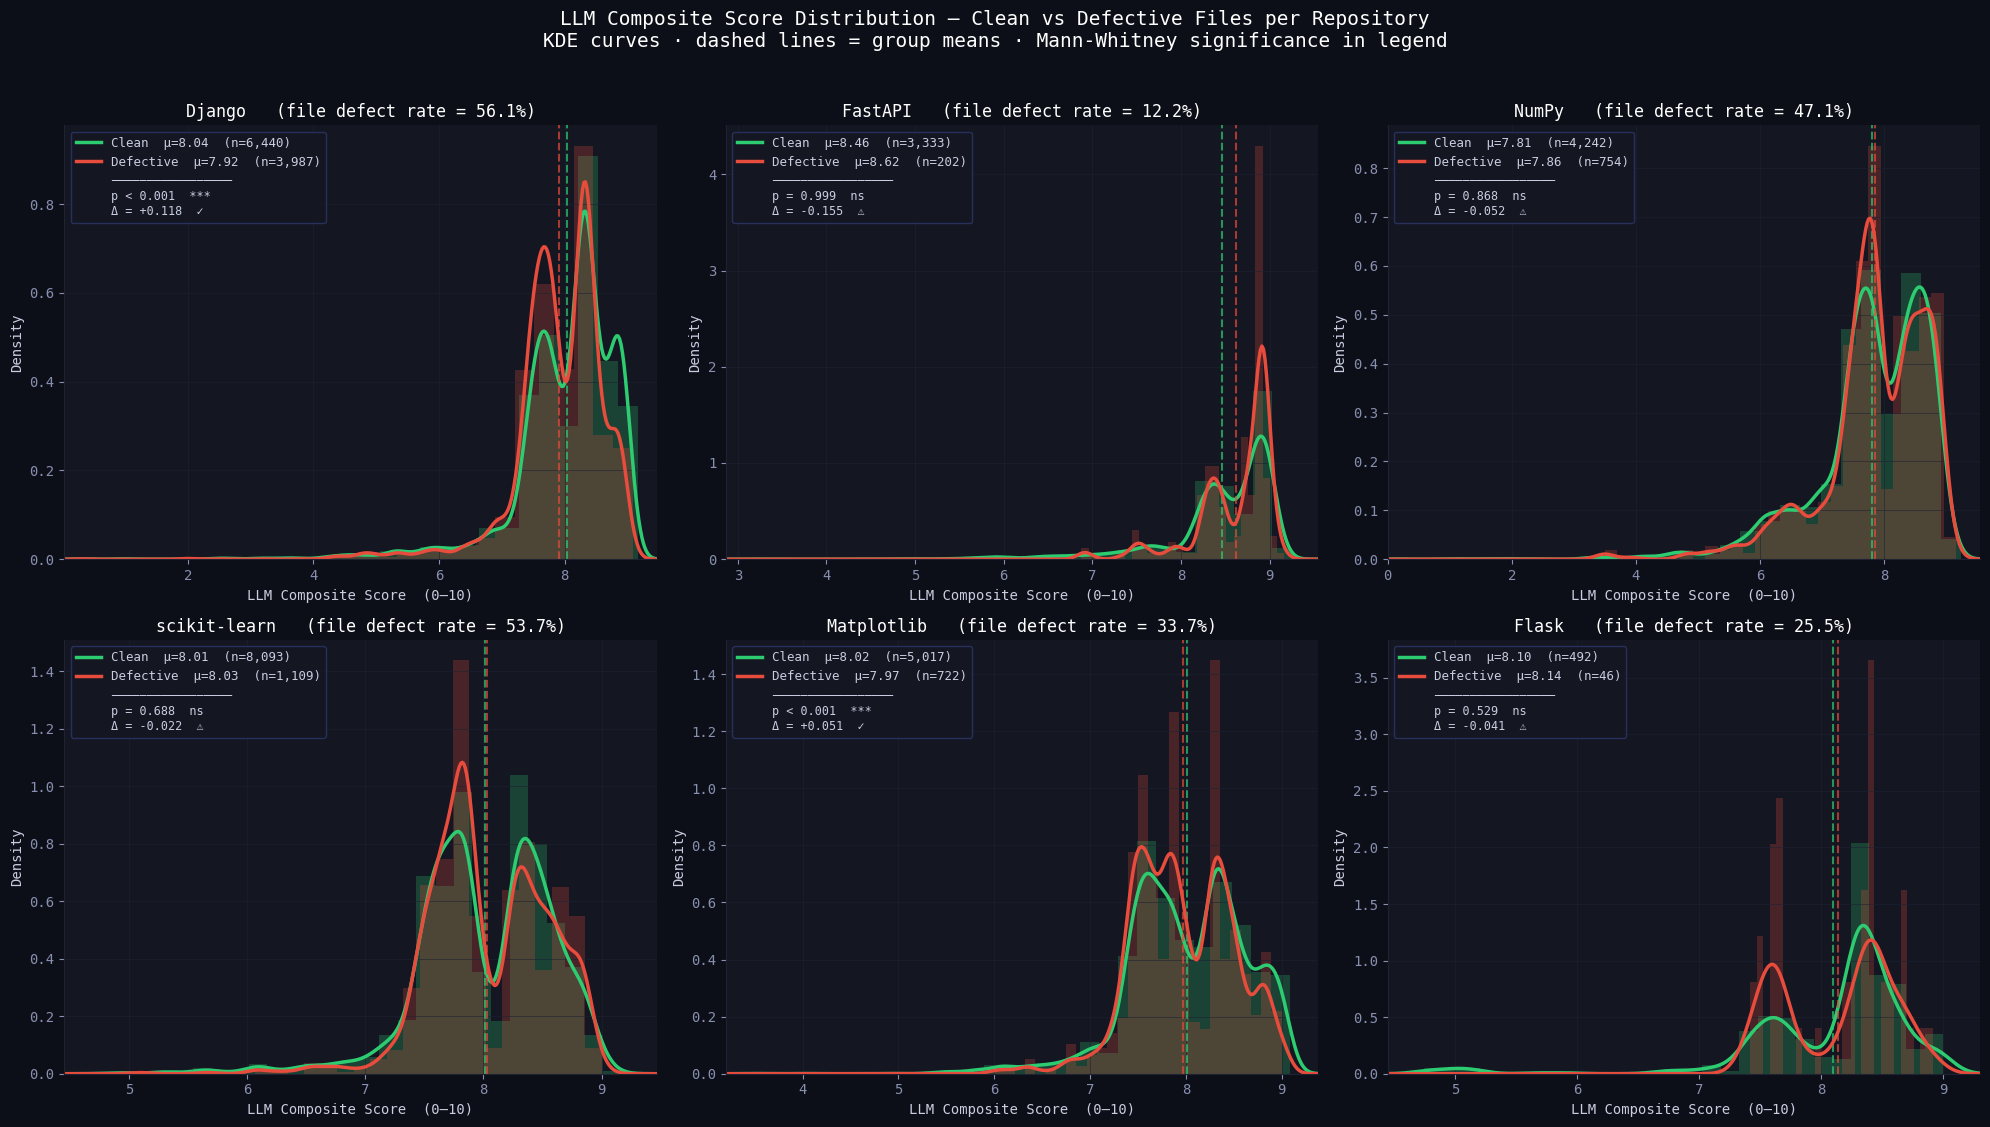

✓  fig_score_dist_per_repo.png saved


In [11]:
# ── New Chart C: LLM Score Distribution — Clean vs Defective per Repository ──
from scipy.stats import gaussian_kde, mannwhitneyu
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

fig, axes = plt.subplots(2, 3, figsize=(20, 11), facecolor=BG)
fig.suptitle(
    "LLM Composite Score Distribution — Clean vs Defective Files per Repository\n"
    "KDE curves · dashed lines = group means · Mann-Whitney significance in legend",
    fontsize=14, color="white", y=1.02
)

repo_order = ["django", "fastapi", "numpy", "scikit-learn", "matplotlib", "flask"]
repo_display = {
    "django":       "Django",
    "fastapi":      "FastAPI",
    "numpy":        "NumPy",
    "scikit-learn": "scikit-learn",
    "matplotlib":   "Matplotlib",
    "flask":        "Flask",
}
repo_fdr = {
    "django": 56.1, "fastapi": 12.2, "numpy": 47.1,
    "scikit-learn": 53.7, "matplotlib": 33.7, "flask": 25.5,
}

for ax, repo in zip(axes.flat, repo_order):
    g      = df_raw[df_raw["repository_name"] == repo].copy()
    sc_cln = g[g["is_defective"] == 0]["llm_quality_score_12d"].dropna()
    sc_def = g[g["is_defective"] == 1]["llm_quality_score_12d"].dropna()

    xmin = max(0, min(sc_cln.min(), sc_def.min()) - 0.3)
    xmax = min(10, max(sc_cln.max(), sc_def.max()) + 0.3)
    xs   = np.linspace(xmin, xmax, 400)

    legend_handles = []

    for scores, label, color in [
        (sc_cln, "Clean",     GREEN),
        (sc_def, "Defective", RED),
    ]:
        ax.hist(scores, bins=28, alpha=0.25, color=color,
                density=True, edgecolor="none")
        if len(scores) >= 5:
            bw = 0.25 if len(scores) < 50 else 0.18
            kde = gaussian_kde(scores, bw_method=bw)
            ax.plot(xs, kde(xs), color=color, lw=2.5)
            ax.axvline(scores.mean(), color=color, lw=1.5, ls="--", alpha=0.7)

        # Build legend handle manually so stats can sit below
        h = mlines.Line2D([], [], color=color, lw=2.5,
                          label=f"{label}  μ={scores.mean():.2f}  (n={len(scores):,})")
        legend_handles.append(h)

    # ── Stats as third legend entry ───────────────────────────────────────────
    if len(sc_def) >= 5 and len(sc_cln) >= 5:
        stat, p = mannwhitneyu(sc_cln, sc_def, alternative="greater")
        p_str   = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
        sig     = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
        delta   = sc_cln.mean() - sc_def.mean()
        sign    = "+" if delta >= 0 else ""
        edge    = GREEN if delta >= 0 else RED
        direction_icon = "✓" if delta >= 0 else "⚠"

        # Invisible line handle — just carries the label text
        stats_handle = mlines.Line2D(
            [], [], color="none", lw=0,
            label=f"─────────────────\n"
                  f"{p_str}  {sig}\n"
                  f"Δ = {sign}{delta:.3f}  {direction_icon}"
        )
        legend_handles.append(stats_handle)

    leg = ax.legend(
        handles=legend_handles,
        fontsize=9,
        loc="upper left",
        framealpha=0.75,
        edgecolor="#2e3a6e",
        facecolor=PANEL,
    )

    # Style the stats text entry differently — make it slightly dimmer
    if len(leg.get_texts()) == 3:
        leg.get_texts()[2].set_color("#c8cde0")
        leg.get_texts()[2].set_fontsize(8.5)

    ax.set_xlim(xmin, xmax)
    ax.set_xlabel("LLM Composite Score  (0–10)", fontsize=10)
    ax.set_ylabel("Density", fontsize=10)
    ax.set_title(
        f"{repo_display[repo]}   (file defect rate = {repo_fdr[repo]:.1f}%)",
        fontsize=12
    )

plt.tight_layout()
plt.savefig("results/fig_score_dist_per_repo.png",
            dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()
print("✓  fig_score_dist_per_repo.png saved")

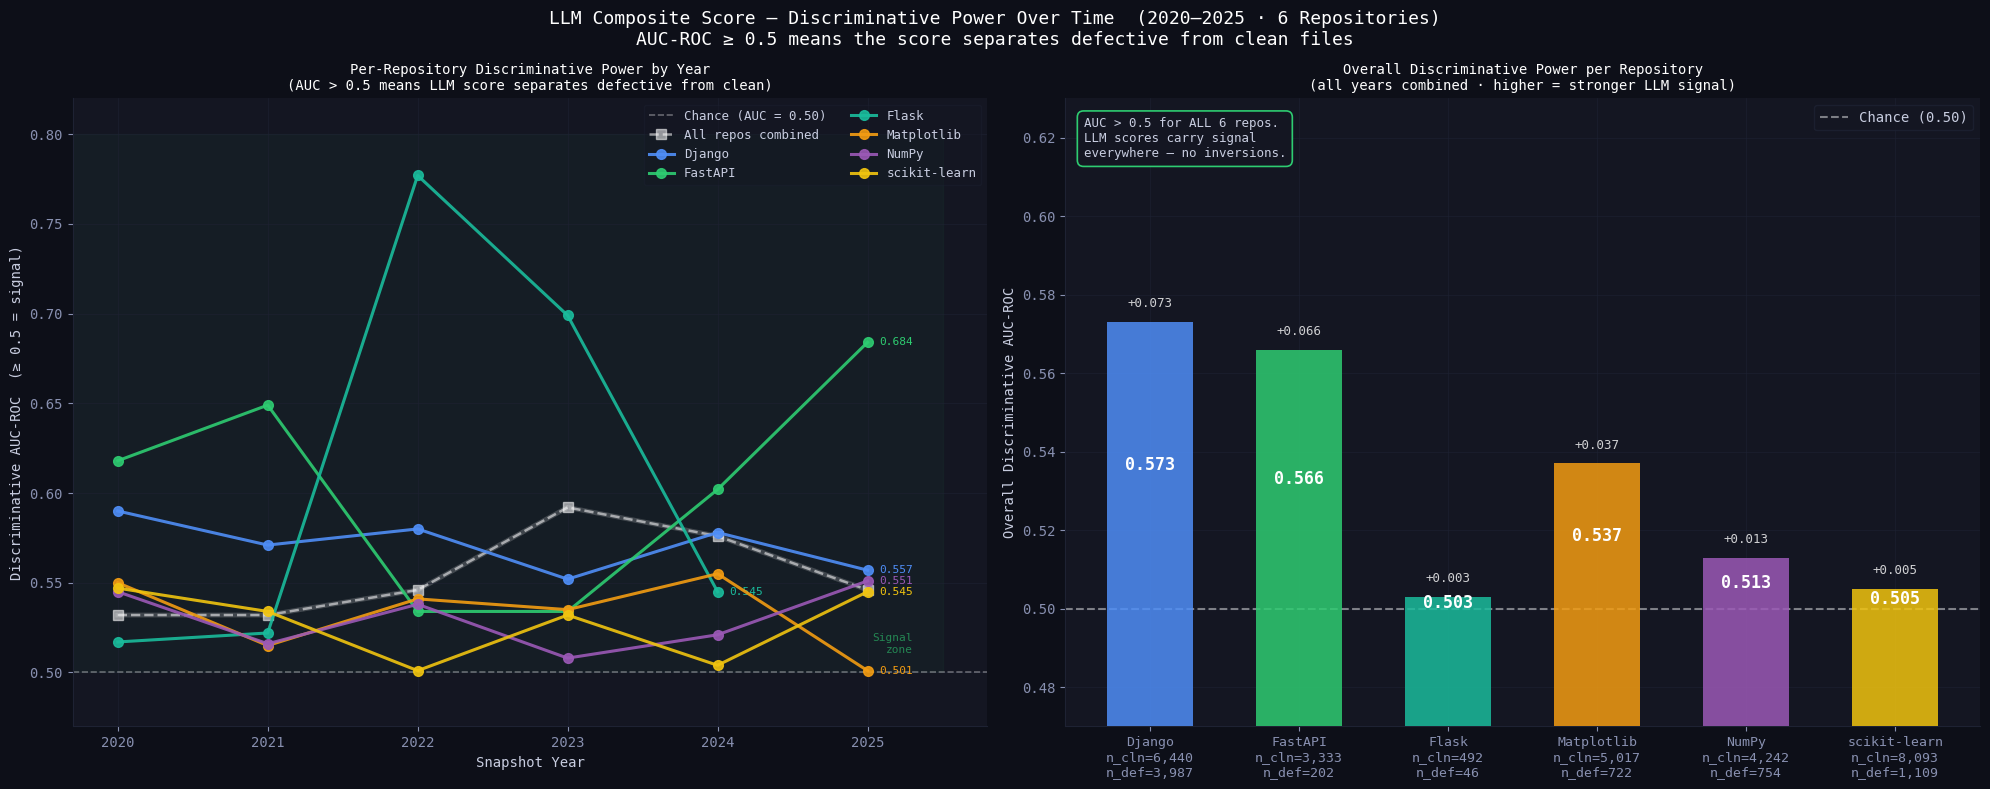

✓  fig_score_stability_time.png saved


In [12]:
# ── New Chart D: LLM Score Stability Over Time (Discriminative Power) ─────────
# Uses AUC-ROC discriminative power (always ≥ 0.5) instead of raw gap.
# AUC = probability that a randomly drawn defective file is correctly ranked
# below (or above) a clean file. Never inverts, never misleads.

fig, axes = plt.subplots(1, 2, figsize=(20, 8), facecolor=BG)
fig.suptitle(
    "LLM Composite Score — Discriminative Power Over Time  (2020–2025 · 6 Repositories)\n"
    "AUC-ROC ≥ 0.5 means the score separates defective from clean files",
    fontsize=13, color="white"
)

# ── Data ───────────────────────────────────────────────────────────────────────
years     = [2020, 2021, 2022, 2023, 2024, 2025]
years_arr = np.array(years)

# Global AUC per year (discriminative power = max(AUC, 1-AUC))
global_auc = [0.532, 0.532, 0.546, 0.592, 0.576, 0.546]
global_n   = [8336,  4921,  6218,  5808,  4514,  4640]

# Per-repo per-year discriminative AUC
repo_data = {
    "Django":       {"color": ACCENT,  "auc": [0.590, 0.571, 0.580, 0.552, 0.578, 0.557]},
    "FastAPI":      {"color": GREEN,   "auc": [0.618, 0.649, 0.534, 0.534, 0.602, 0.684]},
    "Flask":        {"color": TEAL,    "auc": [0.517, 0.522, 0.777, 0.699, 0.545, None  ]},
    "Matplotlib":   {"color": ORANGE,  "auc": [0.550, 0.515, 0.541, 0.535, 0.555, 0.501]},
    "NumPy":        {"color": PURPLE,  "auc": [0.545, 0.516, 0.538, 0.508, 0.521, 0.551]},
    "scikit-learn": {"color": YELLOW,  "auc": [0.547, 0.534, 0.501, 0.532, 0.504, 0.545]},
}

# Per-repo overall discriminative AUC and sample sizes
repo_overall = {
    "Django":       {"auc": 0.573, "nc": 6440,  "nd": 3987},
    "FastAPI":      {"auc": 0.566, "nc": 3333,  "nd":  202},
    "Flask":        {"auc": 0.503, "nc":  492,  "nd":   46},
    "Matplotlib":   {"auc": 0.537, "nc": 5017,  "nd":  722},
    "NumPy":        {"auc": 0.513, "nc": 4242,  "nd":  754},
    "scikit-learn": {"auc": 0.505, "nc": 8093,  "nd": 1109},
}

# ── LEFT: Per-repo line chart over years ──────────────────────────────────────
ax = axes[0]

# Chance baseline
ax.axhline(0.5, color="white", lw=1.2, ls="--", alpha=0.35,
           label="Chance (AUC = 0.50)")

# Global trend as thick background line
ax.plot(years_arr, global_auc, color="white", lw=3.5,
        alpha=0.18, zorder=1)
ax.plot(years_arr, global_auc, "s--", color="white", lw=1.8,
        ms=7, alpha=0.55, zorder=2, label="All repos combined")

# Per-repo lines
for repo, info in repo_data.items():
    auc_vals = info["auc"]
    # Filter out None (Flask 2025)
    yr_valid  = [yr for yr, v in zip(years, auc_vals) if v is not None]
    auc_valid = [v  for v       in auc_vals            if v is not None]
    ax.plot(yr_valid, auc_valid, "o-",
            color=info["color"], lw=2.2, ms=7, zorder=4,
            label=repo, alpha=0.90)
    # Annotate final point
    ax.annotate(f"{auc_valid[-1]:.3f}",
                xy=(yr_valid[-1], auc_valid[-1]),
                xytext=(yr_valid[-1] + 0.08, auc_valid[-1]),
                fontsize=8, color=info["color"], va="center")

# Shade "above chance" area
ax.fill_between([2019.7, 2025.5], [0.5, 0.5], [0.8, 0.8],
                alpha=0.04, color=GREEN, zorder=0)
ax.text(2025.3, 0.51, "Signal\nzone", ha="right", va="bottom",
        fontsize=8, color=GREEN, alpha=0.6)

ax.set_xlim(2019.7, 2025.8)
ax.set_ylim(0.47, 0.82)
ax.set_xticks(years)
ax.set_xlabel("Snapshot Year")
ax.set_ylabel("Discriminative AUC-ROC  (≥ 0.5 = signal)")
ax.set_title("Per-Repository Discriminative Power by Year\n"
             "(AUC > 0.5 means LLM score separates defective from clean)", fontsize=10)
ax.legend(fontsize=9, loc="upper right",
          framealpha=0.4, ncol=2)

# ── RIGHT: Overall per-repo bar — AUC + sample sizes on x-axis ───────────────
ax2 = axes[1]

repo_names    = list(repo_overall.keys())
repo_colors   = [repo_data[r]["color"] for r in repo_names]
repo_aucs     = [repo_overall[r]["auc"] for r in repo_names]
repo_nc_list  = [repo_overall[r]["nc"]  for r in repo_names]
repo_nd_list  = [repo_overall[r]["nd"]  for r in repo_names]
x_pos         = np.arange(len(repo_names))

bars = ax2.bar(x_pos, repo_aucs, color=repo_colors,
               alpha=0.85, width=0.58, edgecolor="none", zorder=3)

# Chance baseline
ax2.axhline(0.5, color="white", lw=1.5, ls="--", alpha=0.45,
            label="Chance (0.50)", zorder=2)

# Value labels inside bars
for bar, auc in zip(bars, repo_aucs):
    ax2.text(bar.get_x() + bar.get_width()/2,
             0.5 + (auc - 0.5)/2,
             f"{auc:.3f}",
             ha="center", va="center",
             fontsize=12, fontweight="bold", color="white", zorder=5)

# "Above chance" delta label above each bar
for xi, auc in enumerate(repo_aucs):
    delta = auc - 0.5
    ax2.text(xi, auc + 0.003,
             f"+{delta:.3f}",
             ha="center", va="bottom",
             fontsize=9, color="white", alpha=0.8)

# X-axis: repo name + n_clean + n_def
xtick_labels = [
    f"{r}\nn_cln={nc:,}\nn_def={nd:,}"
    for r, nc, nd in zip(repo_names, repo_nc_list, repo_nd_list)
]
ax2.set_xticks(x_pos)
ax2.set_xticklabels(xtick_labels, fontsize=9.5)
ax2.set_ylim(0.47, 0.63)
ax2.set_ylabel("Overall Discriminative AUC-ROC")
ax2.set_title("Overall Discriminative Power per Repository\n"
              "(all years combined · higher = stronger LLM signal)", fontsize=10)
ax2.legend(fontsize=10, loc="upper right")

# Insight box
ax2.text(0.02, 0.97,
         "AUC > 0.5 for ALL 6 repos.\n"
         "LLM scores carry signal\n"
         "everywhere — no inversions.",
         transform=ax2.transAxes, fontsize=9,
         va="top", ha="left", color="#c8cde0",
         bbox=dict(boxstyle="round,pad=0.5", facecolor=PANEL,
                   edgecolor=GREEN, lw=1.2))

plt.tight_layout()
plt.savefig("results/fig_score_stability_time.png",
            dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()
print("✓  fig_score_stability_time.png saved")

## 🏆 4 · RQ3 - Classification Performance
> *Does adding LLM features improve defect prediction?  
> Which classifier benefits most?*

In [23]:
from sklearn.metrics import precision_score, recall_score

def run(name,clf,Xtr,Xte,ytr,yte,scaler=None):
    Xt_=scaler.fit_transform(Xtr) if scaler else np.array(Xtr)
    Xe_=scaler.transform(Xte)     if scaler else np.array(Xte)
    clf.fit(Xt_,ytr)
    prob   =clf.predict_proba(Xe_)[:,1]   # test-set probabilities
    prob_tr=clf.predict_proba(Xt_)[:,1]   # train-set probabilities

    # ── Decision threshold tuned on the TRAINING set only (no test leakage) ───
    # Used internally for Precision / Recall / F1; not reported.
    pt,rt,tt = precision_recall_curve(ytr,prob_tr)
    f1_tr    = 2*pt*rt/(pt+rt+1e-9)
    best_thresh = tt[np.argmax(f1_tr[:-1])] if len(tt)>0 else 0.5
    pred=(prob>=best_thresh).astype(int)

    fpr,tpr,_=roc_curve(yte,prob)
    prec,rec,_=precision_recall_curve(yte,prob)   # full PR curve (for plots)
    return {"Classifier":name,
            "AUC_ROC":   round(roc_auc_score(yte,prob),4),
            "Precision": round(precision_score(yte,pred,zero_division=0),4),  # all test files
            "Recall":    round(recall_score(yte,pred,zero_division=0),4),     # all test files
            "F1":        round(f1_score(yte,pred,zero_division=0),4),
            "_prob":prob,"_pred":pred,"_yte":yte.values,
            "_fpr":fpr,"_tpr":tpr,"_prec":prec,"_rec":rec}

# ── class_weight always balanced — handles temporal split imbalance ────────────
CLFS=[("Logistic Regression",LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42),StandardScaler()),
      ("Random Forest",RandomForestClassifier(n_estimators=300,class_weight="balanced",random_state=42,n_jobs=-1),None),
      ("LightGBM",lgb.LGBMClassifier(n_estimators=300,learning_rate=0.05,class_weight="balanced",random_state=42,verbosity=-1,n_jobs=-1),None)]

res={}
for fs,fl in [("metrics-only",avail_m),("metrics+LLM",avail_l)]:
    res[fs]={}
    Xtr=X_tr[fl].fillna(0); Xte=X_te[fl].fillna(0)
    print(f"\n  {fs}  ({len(fl)} features)")
    for name,clf,scaler in CLFS:
        r=run(name,clf,Xtr,Xte,y_tr,y_te,scaler)
        res[fs][name]=r
        print(f"    {name:<22} AUC={r['AUC_ROC']:.4f}  Precision={r['Precision']:.4f}  "
              f"Recall={r['Recall']:.4f}  F1={r['F1']:.4f}")


  metrics-only  (11 features)
    Logistic Regression    AUC=0.8526  Precision=0.8180  Recall=0.7904  F1=0.8040
    Random Forest          AUC=0.8686  Precision=0.9017  Recall=0.5254  F1=0.6639
    LightGBM               AUC=0.8534  Precision=0.8742  Recall=0.6606  F1=0.7525

  metrics+LLM  (24 features)
    Logistic Regression    AUC=0.8465  Precision=0.8093  Recall=0.7893  F1=0.7992
    Random Forest          AUC=0.8806  Precision=0.9089  Recall=0.5478  F1=0.6836
    LightGBM               AUC=0.8635  Precision=0.8876  Recall=0.6482  F1=0.7492


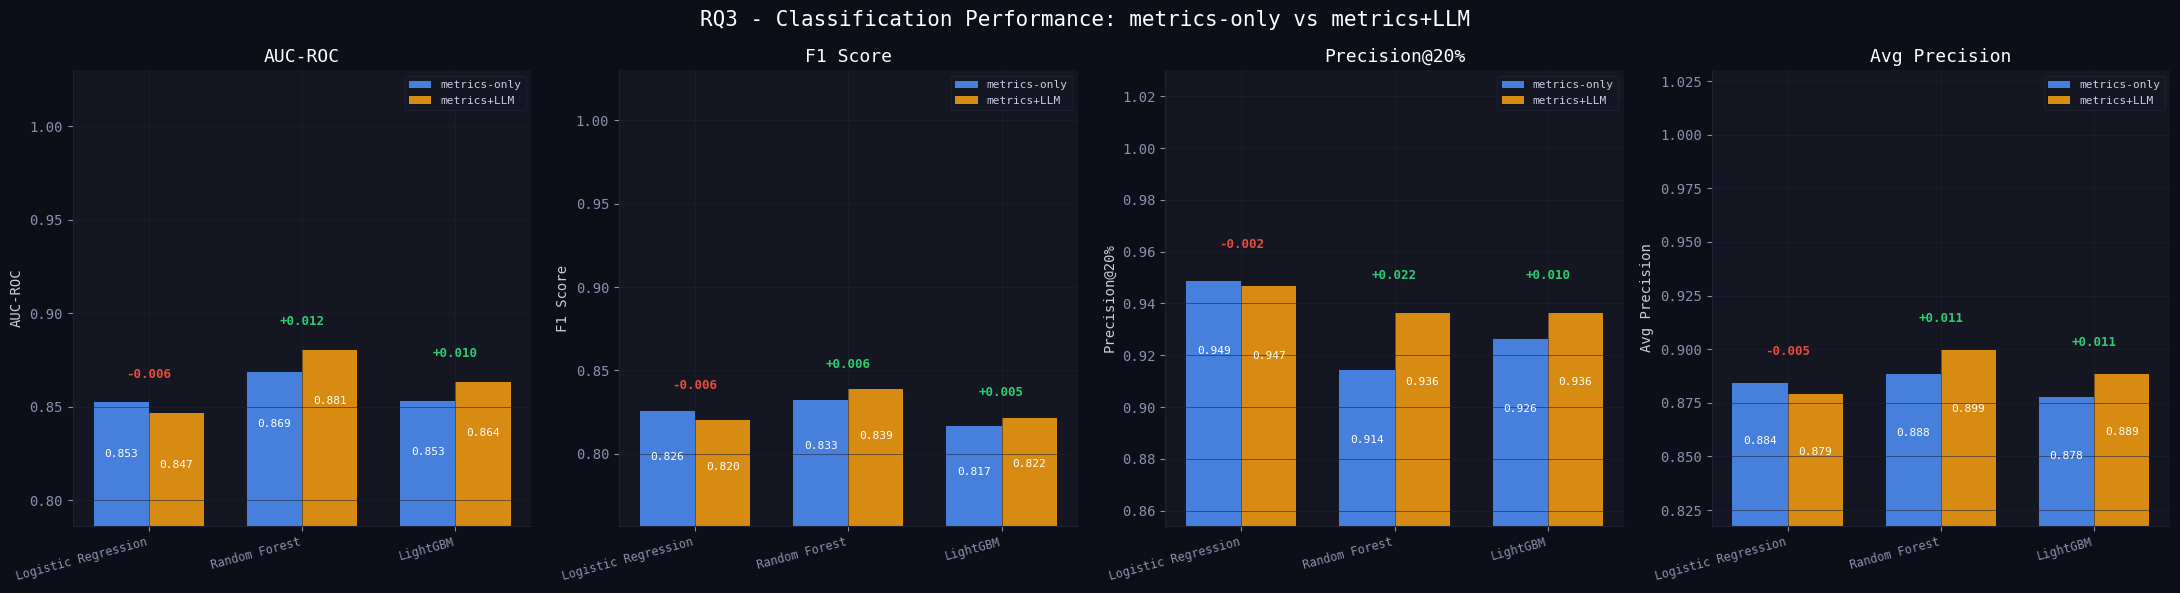

✓  fig5_rq3_bars.png


In [14]:
# ── RQ3 Chart 1: 4-metric grouped bars ────────────────────────────────────────
fig,axes=plt.subplots(1,4,figsize=(22,6),facecolor=BG)
fig.suptitle("RQ3 - Classification Performance: metrics-only vs metrics+LLM",fontsize=15,color="white")

metrics_show=[("AUC_ROC","AUC-ROC"),("F1","F1 Score"),("P20","Precision@20%"),("AP","Avg Precision")]
clf_names=[c[0] for c in CLFS]

for ax,(metric,title) in zip(axes,metrics_show):
    x=np.arange(len(clf_names)); w=0.36
    vm=[res["metrics-only"][c][metric] for c in clf_names]
    vl=[res["metrics+LLM"][c][metric]  for c in clf_names]
    b1=ax.bar(x-w/2,vm,w,color=ACCENT,alpha=0.88,label="metrics-only",edgecolor="none")
    b2=ax.bar(x+w/2,vl,w,color=ORANGE,alpha=0.88,label="metrics+LLM", edgecolor="none")
    ax.set_xticks(x); ax.set_xticklabels(clf_names,rotation=15,ha="right",fontsize=8.5)
    ax.set_ylabel(title); ax.set_title(title)
    mn=min(vm+vl); ax.set_ylim(max(0,mn-0.06),1.03)
    ax.legend(fontsize=8)
    # delta annotations
    for xi,(v1,v2) in enumerate(zip(vm,vl)):
        d=v2-v1; sign="+"; color=GREEN if d>=0 else RED
        if d<0: sign=""
        ax.text(xi,max(v1,v2)+0.013,f"{sign}{d:.3f}",
                ha="center",fontsize=9,color=color,fontweight="bold")
    for bar in b1+b2:
        ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()-0.025,
                f"{bar.get_height():.3f}",ha="center",va="top",fontsize=8,color="white")

plt.tight_layout()
plt.savefig("results/fig5_rq3_bars.png",dpi=150,bbox_inches="tight",facecolor=BG)
plt.show(); print("✓  fig5_rq3_bars.png")

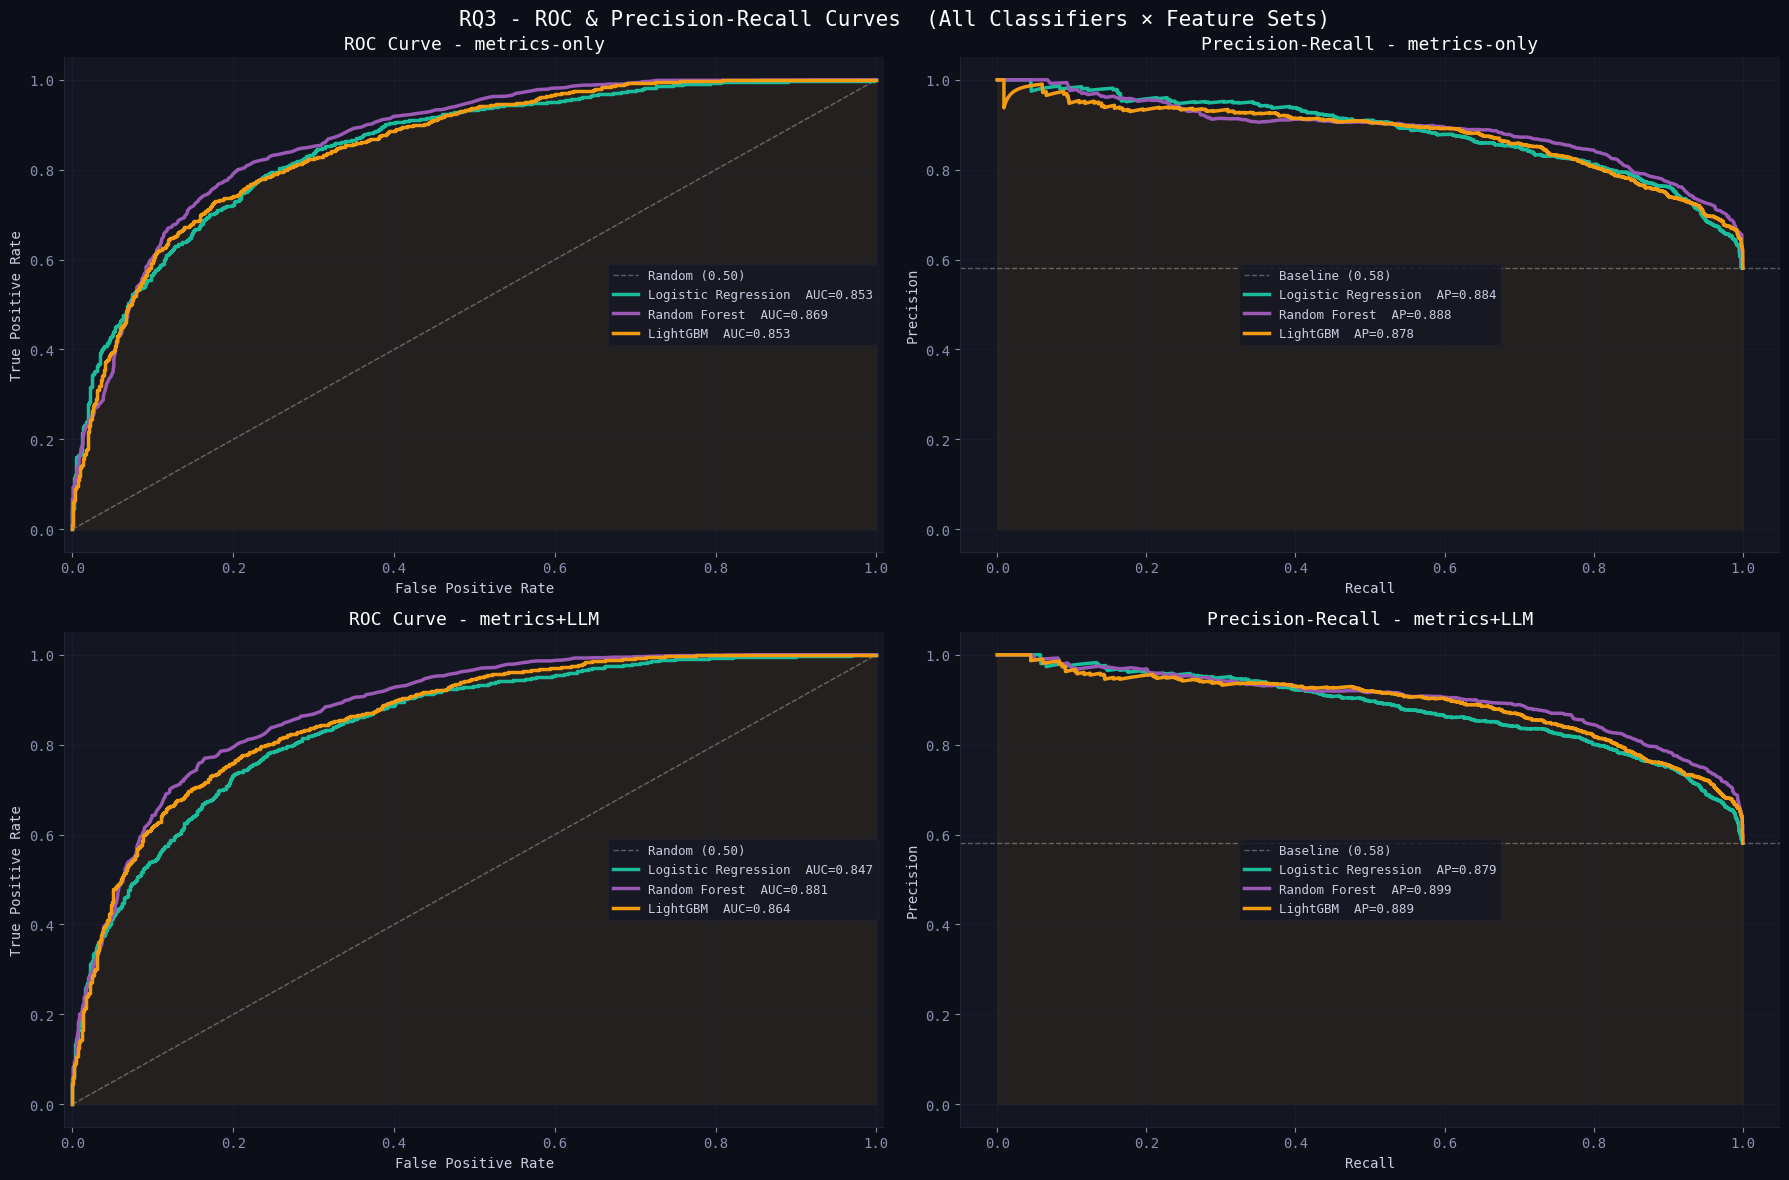

✓  fig6_rq3_roc_pr.png


In [15]:
# ── RQ3 Chart 2: ROC + PR curves ──────────────────────────────────────────────
fig,axes=plt.subplots(2,2,figsize=(18,12),facecolor=BG)
fig.suptitle("RQ3 - ROC & Precision-Recall Curves  (All Classifiers × Feature Sets)",fontsize=15,color="white")

clf_colors={c[0]:col for c,col in zip(CLFS,[TEAL,PURPLE,ORANGE])}

for row,fs in enumerate(["metrics-only","metrics+LLM"]):
    # ROC
    ax=axes[row][0]; ax.set_facecolor(PANEL)
    ax.fill_between([0,1],[0,1],[0,1],alpha=0.04,color="white")
    ax.plot([0,1],[0,1],"w--",lw=1,alpha=0.3,label="Random (0.50)")
    for name,_,_ in CLFS:
        r=res[fs][name]
        ax.plot(r["_fpr"],r["_tpr"],color=clf_colors[name],lw=2.5,
                label=f"{name}  AUC={r['AUC_ROC']:.3f}")
    ax.fill_between(res[fs]["LightGBM"]["_fpr"],
                    res[fs]["LightGBM"]["_tpr"],alpha=0.08,color=ORANGE)
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.set_title(f"ROC Curve - {fs}"); ax.legend(); ax.set_xlim(-0.01,1.01)

    # PR
    ax=axes[row][1]; ax.set_facecolor(PANEL)
    baseline=y_te.mean()
    ax.axhline(baseline,color="white",lw=1,ls="--",alpha=0.3,label=f"Baseline ({baseline:.2f})")
    for name,_,_ in CLFS:
        r=res[fs][name]
        ax.plot(r["_rec"],r["_prec"],color=clf_colors[name],lw=2.5,
                label=f"{name}  AP={r['AP']:.3f}")
    ax.fill_between(res[fs]["LightGBM"]["_rec"],
                    res[fs]["LightGBM"]["_prec"],alpha=0.08,color=ORANGE)
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"Precision-Recall - {fs}"); ax.legend()

plt.tight_layout()
plt.savefig("results/fig6_rq3_roc_pr.png",dpi=150,bbox_inches="tight",facecolor=BG)
plt.show(); print("✓  fig6_rq3_roc_pr.png")

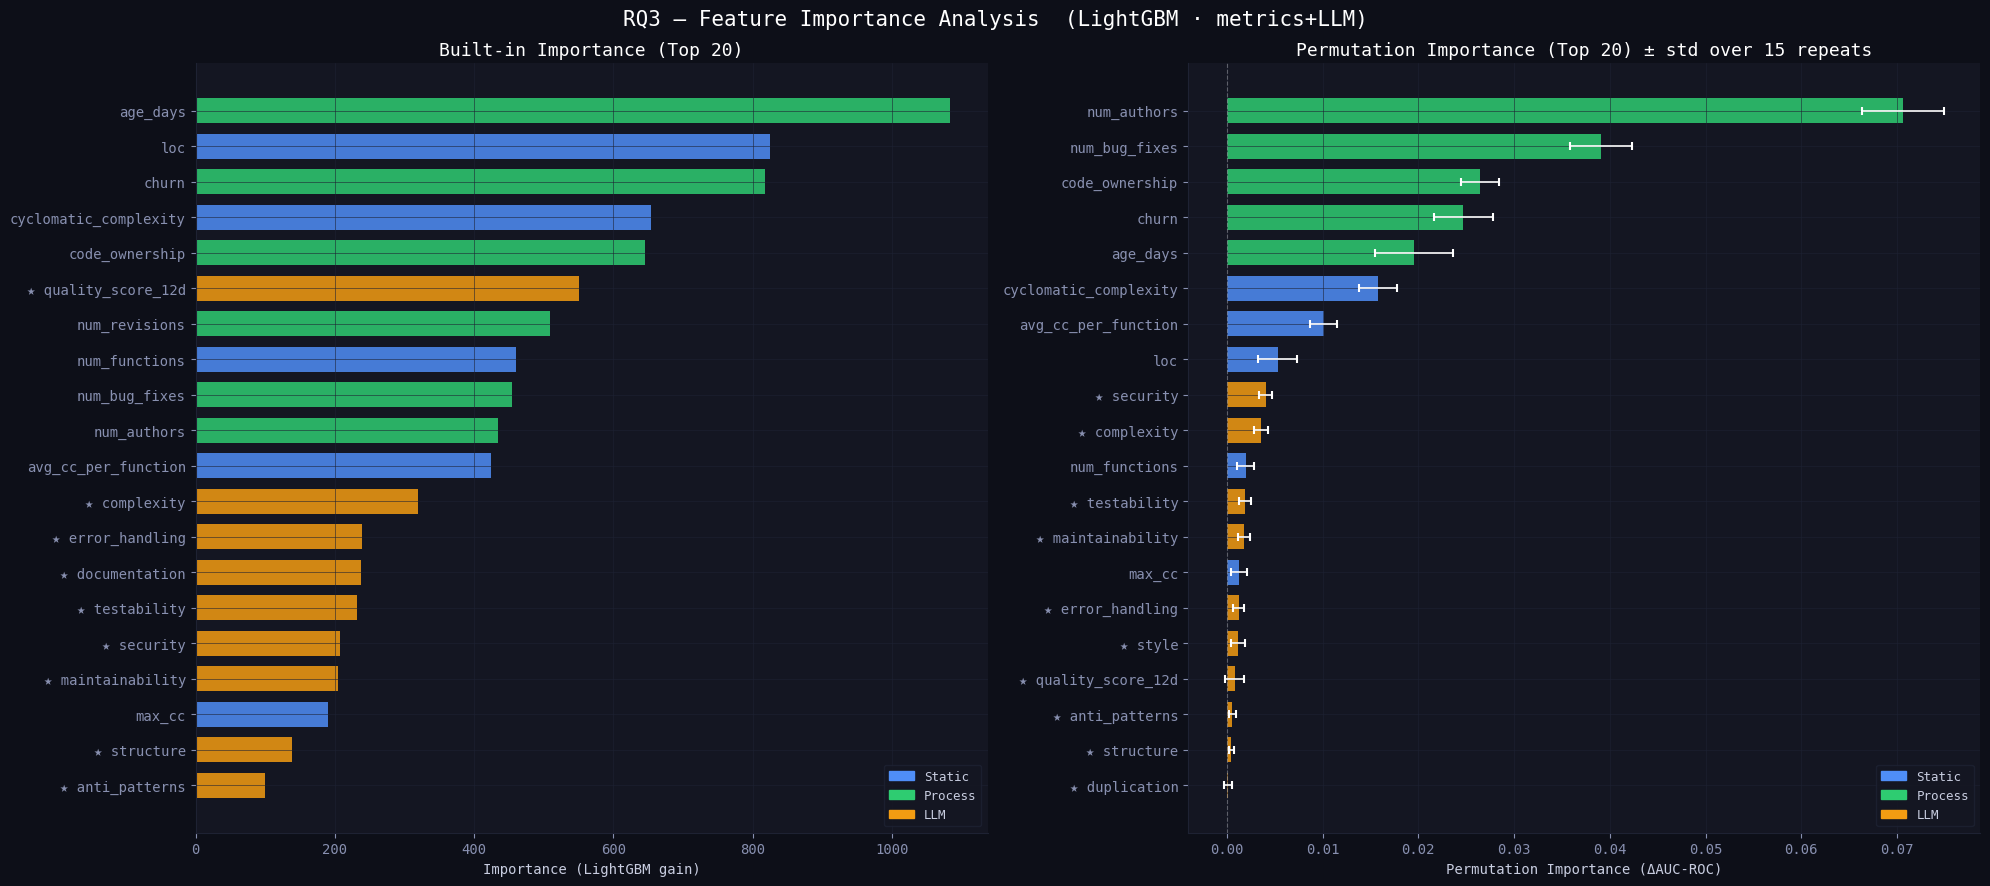

✓  fig7_importance.png


In [16]:
# ── RQ3 Chart 3: Feature importance (built-in + permutation) ─────────────────
lgbm=lgb.LGBMClassifier(n_estimators=300,learning_rate=0.05,random_state=42,verbosity=-1,n_jobs=-1)
Xtr_f=X_tr[avail_l].fillna(0); Xte_f=X_te[avail_l].fillna(0)
lgbm.fit(Xtr_f,y_tr)
fi=pd.DataFrame({"Feature":avail_l,"Importance":lgbm.feature_importances_})
fi["Group"]=fi["Feature"].apply(lambda f:"Static" if f in STATIC else("Process" if f in PROCESS else "LLM"))

perm=permutation_importance(lgbm,Xte_f,y_te,n_repeats=15,random_state=42,n_jobs=-1,scoring="roc_auc")
perm_df=pd.DataFrame({"Feature":avail_l,"Importance":perm.importances_mean,"Std":perm.importances_std})
perm_df["Group"]=perm_df["Feature"].apply(lambda f:"Static" if f in STATIC else("Process" if f in PROCESS else "LLM"))

fig,axes=plt.subplots(1,2,figsize=(20,9),facecolor=BG)
fig.suptitle("RQ3 — Feature Importance Analysis  (LightGBM · metrics+LLM)",fontsize=15,color="white")

for ax,df_imp,title,xlabel in [
    (axes[0], fi.sort_values("Importance",ascending=True).tail(20),
     "Built-in Importance (Top 20)", "Importance (LightGBM gain)"),
    (axes[1], perm_df.sort_values("Importance",ascending=True).tail(20),
     "Permutation Importance (Top 20) ± std over 15 repeats", "Permutation Importance (ΔAUC-ROC)")]:
    bc=[GROUP_COLORS[g] for g in df_imp["Group"]]
    if "Std" in df_imp.columns:
        ax.barh(df_imp["Feature"].str.replace("llm_","★ "),df_imp["Importance"],
                xerr=df_imp["Std"],color=bc,alpha=0.85,height=0.7,edgecolor="none",
                capsize=3,error_kw={"ecolor":"white","capthick":1.5,"elinewidth":1.2})
        ax.axvline(0,color="white",lw=0.8,ls="--",alpha=0.3)
    else:
        ax.barh(df_imp["Feature"].str.replace("llm_","★ "),df_imp["Importance"],
                color=bc,alpha=0.85,height=0.7,edgecolor="none")
    ax.set_xlabel(xlabel); ax.set_title(title)
    patches=[mpatches.Patch(color=c,label=g) for g,c in GROUP_COLORS.items()]
    ax.legend(handles=patches)

plt.tight_layout()
plt.savefig("results/fig7_importance.png",dpi=150,bbox_inches="tight",facecolor=BG)
plt.show(); print("✓  fig7_importance.png")

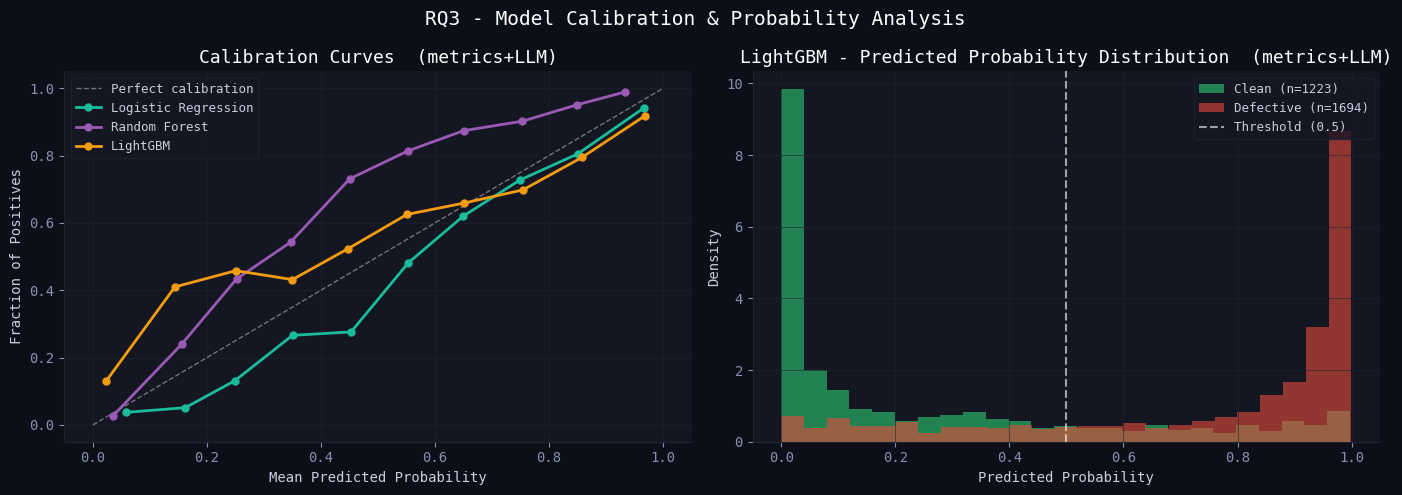

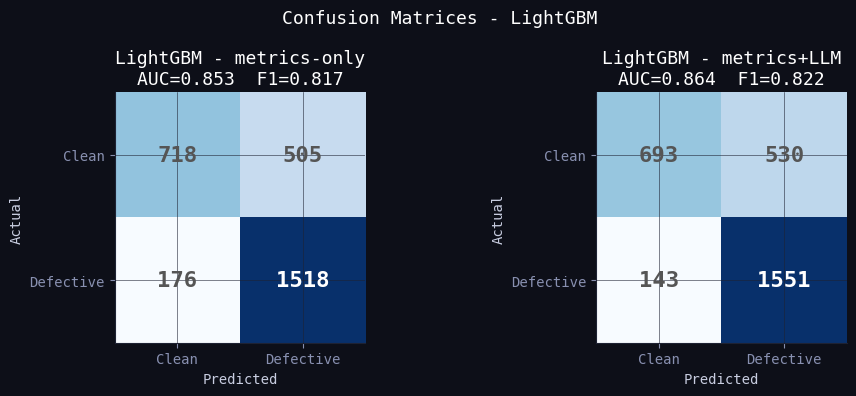

✓  fig8_calibration.png  fig9_confusion.png


In [17]:
# ── RQ3 Chart 4: Calibration + distributions + confusion matrices ─────────────
fig,axes=plt.subplots(1,2,figsize=(14,5),facecolor=BG)
fig.suptitle("RQ3 - Model Calibration & Probability Analysis",fontsize=14,color="white")

ax1=axes[0]
ax1.plot([0,1],[0,1],"w--",lw=1,alpha=0.4,label="Perfect calibration")
for name,_,_ in CLFS:
    r=res["metrics+LLM"][name]
    fp2,mp2=calibration_curve(r["_yte"],r["_prob"],n_bins=10)
    ax1.plot(mp2,fp2,"o-",color=clf_colors[name],lw=2,ms=5,label=name)
ax1.set_xlabel("Mean Predicted Probability"); ax1.set_ylabel("Fraction of Positives")
ax1.set_title("Calibration Curves  (metrics+LLM)"); ax1.legend()

ax2=axes[1]
r=res["metrics+LLM"]["LightGBM"]
prob_def=r["_prob"][r["_yte"]==1]; prob_cln=r["_prob"][r["_yte"]==0]
ax2.hist(prob_cln,bins=25,alpha=0.6,color=GREEN,density=True,label=f"Clean (n={len(prob_cln)})")
ax2.hist(prob_def,bins=25,alpha=0.6,color=RED,  density=True,label=f"Defective (n={len(prob_def)})")
ax2.axvline(0.5,color="white",lw=1.5,ls="--",alpha=0.6,label="Threshold (0.5)")
ax2.set_xlabel("Predicted Probability"); ax2.set_ylabel("Density")
ax2.set_title("LightGBM - Predicted Probability Distribution  (metrics+LLM)"); ax2.legend()

plt.tight_layout()
plt.savefig("results/fig8_calibration.png",dpi=150,bbox_inches="tight",facecolor=BG)
plt.show()

# confusion matrices
fig2,ax3s=plt.subplots(1,2,figsize=(10,4),facecolor=BG)
fig2.suptitle("Confusion Matrices - LightGBM",color="white",fontsize=13)
for ax_cm,fs in zip(ax3s,["metrics-only","metrics+LLM"]):
    r=res[fs]["LightGBM"]
    cm=confusion_matrix(r["_yte"],r["_pred"])
    ax_cm.imshow(cm,cmap="Blues",interpolation="nearest")
    ax_cm.set_xticks([0,1]); ax_cm.set_yticks([0,1])
    ax_cm.set_xticklabels(["Clean","Defective"])
    ax_cm.set_yticklabels(["Clean","Defective"])
    ax_cm.set_xlabel("Predicted"); ax_cm.set_ylabel("Actual")
    ax_cm.set_title(f"LightGBM - {fs}\nAUC={r['AUC_ROC']:.3f}  F1={r['F1']:.3f}")
    for i in range(2):
        for j in range(2):
            ax_cm.text(j,i,f"{cm[i,j]}",ha="center",va="center",fontsize=16,fontweight="bold",
                       color="white" if cm[i,j]>cm.max()/2 else "#555")
fig2.patch.set_facecolor(BG)
plt.tight_layout()
plt.savefig("results/fig9_confusion.png",dpi=150,bbox_inches="tight",facecolor=BG)
plt.show(); print("✓  fig8_calibration.png  fig9_confusion.png")


# 5. RQ4 - CROSS-REPOSITORY GENERALISATION (Leave-One-Repo-Out)


  RQ4 - CROSS-REPOSITORY GENERALISATION
  Leave-One-Repo-Out: train on N-1 repos, test on held-out repo

  Held-out: django          train=3,728  test=1,743  test_defect=56.1%
    metrics-only   AUC=0.8247  Precision=0.9332  Recall=0.4141
    metrics+LLM    AUC=0.8015  Precision=0.9450  Recall=0.3691

  Held-out: fastapi         train=4,160  test=1,311  test_defect=12.2%
    metrics-only   AUC=0.8769  Precision=0.4457  Recall=0.5125
    metrics+LLM    AUC=0.8888  Precision=0.4533  Recall=0.6062

  Held-out: flask           train=5,377  test=94  test_defect=25.5%
    metrics-only   AUC=0.7113  Precision=0.3696  Recall=0.7083
    metrics+LLM    AUC=0.7637  Precision=0.3750  Recall=0.7500

  Held-out: matplotlib      train=4,699  test=772  test_defect=33.4%
    metrics-only   AUC=0.9015  Precision=0.6968  Recall=0.8372
    metrics+LLM    AUC=0.9030  Precision=0.6951  Recall=0.8217

  Held-out: numpy           train=4,696  test=775  test_defect=47.2%
    metrics-only   AUC=0.8392  Precisio

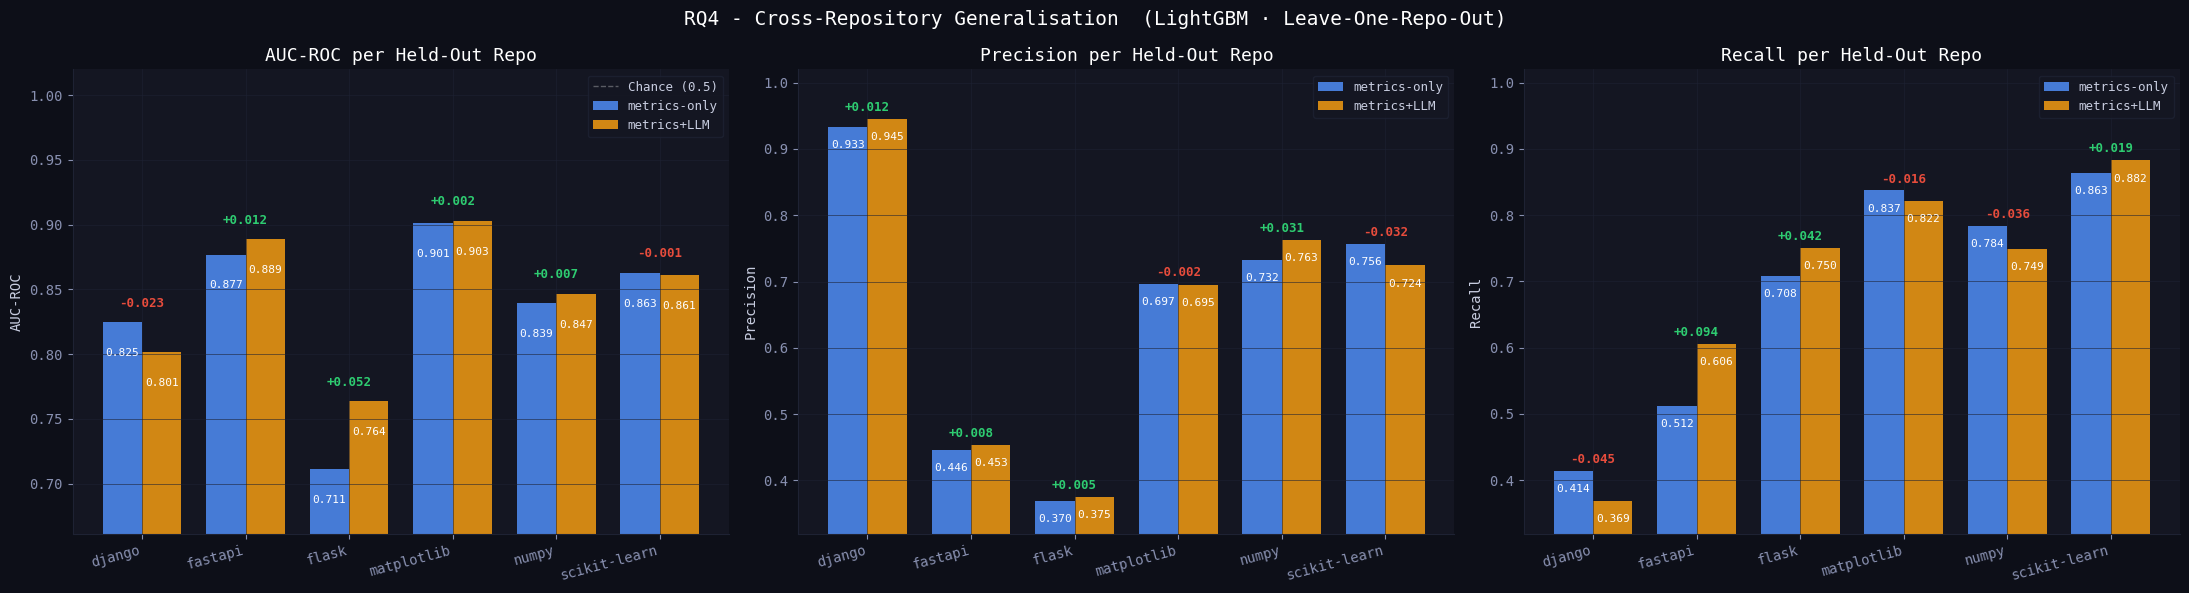


  RQ4 Summary (LightGBM):
  Held-out          metrics-only AUC  metrics+LLM AUC    Delta
  ------------------------------------------------------------
  django                      0.8247           0.8015 -0.0232
  fastapi                     0.8769           0.8888 + 0.0119
  flask                       0.7113           0.7637 + 0.0524
  matplotlib                  0.9015           0.9030 + 0.0015
  numpy                       0.8392           0.8466 + 0.0074
  scikit-learn                0.8627           0.8614 -0.0013
  MEAN                        0.8361           0.8442 + 0.0081

  ✓  Saved → results/rq4_crossrepo.csv  +  results/fig_rq4_crossrepo.png


In [22]:
from sklearn.metrics import precision_score, recall_score, precision_recall_curve

# RQ4 - CROSS-REPOSITORY GENERALISATION (Leave-One-Repo-Out)

print("="*65)
print("  RQ4 - CROSS-REPOSITORY GENERALISATION")
print("  Leave-One-Repo-Out: train on N-1 repos, test on held-out repo")
print("="*65)

if "repository_name" not in df.columns or df["repository_name"].nunique() < 2:
    print("  ⚠ Only one repo loaded — RQ4 requires multiple repos")
else:
    repos      = sorted(df["repository_name"].unique())
    rq4_rows   = []
    clf_colors = {"Logistic Regression":TEAL,"Random Forest":PURPLE,"LightGBM":ORANGE}

    for held_out in repos:
        df_tr = df[df["repository_name"] != held_out]
        df_te = df[df["repository_name"] == held_out]
        y_tr4 = df_tr[TARGET]; y_te4 = df_te[TARGET]

        if y_te4.nunique() < 2 or len(df_te) < 20:
            print(f"\n  ⚠ Skipping {held_out} — too small (n={len(df_te)})")
            continue

        print(f"\n  Held-out: {held_out:<15} "
              f"train={len(df_tr):,}  test={len(df_te):,}  "
              f"test_defect={y_te4.mean()*100:.1f}%")

        for fs, fl in [("metrics-only", avail_m), ("metrics+LLM", avail_l)]:
            Xtr4 = df_tr[fl].fillna(0)
            Xte4 = df_te[fl].fillna(0)
            clf  = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05,
                                       class_weight="balanced", random_state=42,
                                       verbosity=-1, n_jobs=-1)
            clf.fit(Xtr4, y_tr4)
            prob    = clf.predict_proba(Xte4)[:,1]    # held-out repo probabilities
            prob_tr = clf.predict_proba(Xtr4)[:,1]    # training repos probabilities

            # ── Threshold tuned on TRAINING repos only (no leakage from held-out) ──
            pt, rt, tt = precision_recall_curve(y_tr4, prob_tr)
            f1_tr = 2*pt*rt/(pt+rt+1e-9)
            best_thresh = tt[np.argmax(f1_tr[:-1])] if len(tt)>0 else 0.5
            pred = (prob >= best_thresh).astype(int)

            auc   = round(roc_auc_score(y_te4, prob), 4)
            precv = round(precision_score(y_te4, pred, zero_division=0), 4)   # all held-out files
            recv  = round(recall_score(y_te4, pred, zero_division=0), 4)      # all held-out files
            rq4_rows.append({"held_out": held_out, "feature_set": fs,
                             "AUC_ROC": auc, "Precision": precv, "Recall": recv,
                             "n_train": len(df_tr), "n_test": len(df_te)})
            print(f"    {fs:<14} AUC={auc:.4f}  Precision={precv:.4f}  Recall={recv:.4f}")

    df_rq4 = pd.DataFrame(rq4_rows)
    df_rq4.to_csv("results/rq4_crossrepo.csv", index=False)

    # ── RQ4 chart ─────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 3, figsize=(22, 6), facecolor=BG)
    fig.suptitle("RQ4 - Cross-Repository Generalisation  (LightGBM · Leave-One-Repo-Out)",
                 fontsize=14, color="white")

    for ax, metric, title in [(axes[0],"AUC_ROC",  "AUC-ROC"),
                               (axes[1],"Precision","Precision"),
                               (axes[2],"Recall",   "Recall")]:
        held_repos = df_rq4["held_out"].unique()
        x = np.arange(len(held_repos)); w = 0.38
        vm = [df_rq4[(df_rq4["held_out"]==r)&(df_rq4["feature_set"]=="metrics-only")][metric].values[0]
              for r in held_repos]
        vl = [df_rq4[(df_rq4["held_out"]==r)&(df_rq4["feature_set"]=="metrics+LLM")][metric].values[0]
              for r in held_repos]
        b1 = ax.bar(x-w/2, vm, w, color=ACCENT, alpha=0.85, label="metrics-only", edgecolor="none")
        b2 = ax.bar(x+w/2, vl, w, color=ORANGE, alpha=0.85, label="metrics+LLM",  edgecolor="none")
        ax.set_xticks(x); ax.set_xticklabels(held_repos, rotation=15, ha="right", fontsize=10)
        if metric == "AUC_ROC":
            ax.axhline(0.5, color="white", lw=1, ls="--", alpha=0.3, label="Chance (0.5)")
        ax.set_ylabel(title); ax.set_title(f"{title} per Held-Out Repo")
        ax.set_ylim(max(0, min(vm+vl)-0.05), 1.02)
        ax.legend(fontsize=9)
        # delta annotations
        for xi, (v1, v2) in enumerate(zip(vm, vl)):
            d = v2-v1; sign = "+" if d>=0 else ""
            color = GREEN if d>=0 else RED
            ax.text(xi, max(v1,v2)+0.012, f"{sign}{d:.3f}",
                    ha="center", fontsize=9, color=color, fontweight="bold")
        for bar in b1+b2:
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()-0.02,
                    f"{bar.get_height():.3f}", ha="center", va="top",
                    fontsize=8, color="white")

    plt.tight_layout()
    plt.savefig("results/fig_rq4_crossrepo.png", dpi=150, bbox_inches="tight", facecolor=BG)
    plt.show()

    # Summary
    print(f"\n  RQ4 Summary (LightGBM):")
    print(f"  {'Held-out':<15} {'metrics-only AUC':>18} {'metrics+LLM AUC':>16} {'Delta':>8}")
    print(f"  {'-'*60}")
    for repo in repos:
        sub = df_rq4[df_rq4["held_out"]==repo]
        if len(sub) == 0: continue
        m_auc = sub[sub["feature_set"]=="metrics-only"]["AUC_ROC"].values[0]
        l_auc = sub[sub["feature_set"]=="metrics+LLM"]["AUC_ROC"].values[0]
        d = l_auc - m_auc
        sign = "+" if d>=0 else ""
        print(f"  {repo:<15} {m_auc:>18.4f} {l_auc:>16.4f} {sign}{d:>7.4f}")
    m_avg = df_rq4[df_rq4["feature_set"]=="metrics-only"]["AUC_ROC"].mean()
    l_avg = df_rq4[df_rq4["feature_set"]=="metrics+LLM"]["AUC_ROC"].mean()
    print(f"  {'MEAN':<15} {m_avg:>18.4f} {l_avg:>16.4f} {'+' if l_avg>=m_avg else ''}{l_avg-m_avg:>7.4f}")
    print(f"\n  ✓  Saved → results/rq4_crossrepo.csv  +  results/fig_rq4_crossrepo.png")

## 📋 6 · Summary Dashboard

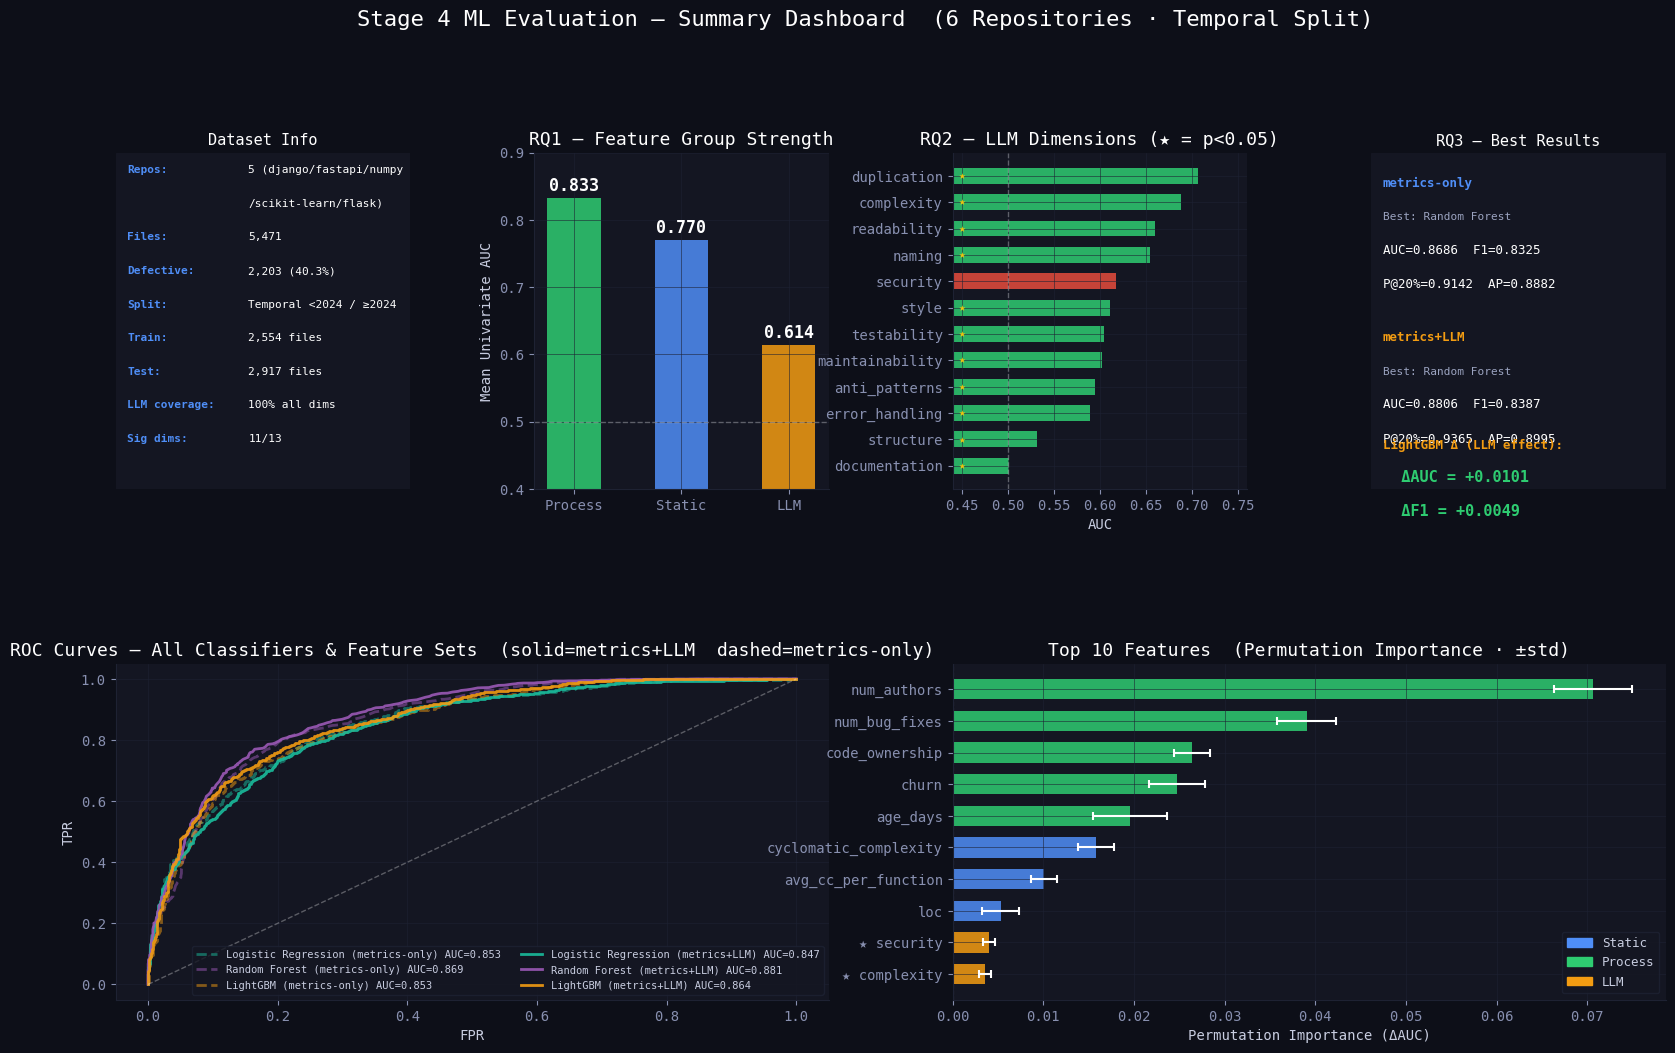


  STAGE 4 FINAL RESULTS — 5 REPOSITORIES
  Dataset  : 5,471 files across 5 repos  |  40.3% defective
  Split    : Temporal  (2,554 train <2024 / 2,917 test ≥2024)

  RQ1  Process > Static > LLM
       Process    mean AUC = 0.8328
       Static     mean AUC = 0.7704
       LLM        mean AUC = 0.6144

  RQ2  11/12 significant  |  mean AUC 0.6134  |  0 flat

  RQ3  metrics-only    best=Random Forest          AUC=0.8686  F1=0.8325
  RQ3  metrics+LLM     best=Random Forest          AUC=0.8806  F1=0.8387
       LightGBM ΔAUC=+0.0101  ΔF1=+0.0049

  RQ4  Cross-repo results above

  ✓  All figures saved to results/  (10 PNG files)


In [19]:
fig=plt.figure(figsize=(20,11),facecolor=BG)
fig.suptitle("Stage 4 ML Evaluation — Summary Dashboard  (6 Repositories · Temporal Split)",
             fontsize=16,color="white",y=1.01)
gs=gridspec.GridSpec(2,4,figure=fig,hspace=0.52,wspace=0.42)

# ── Stats card ────────────────────────────────────────────────────────────────
ax0=fig.add_subplot(gs[0,0]); ax0.axis("off")
ax0.add_patch(plt.Rectangle((0,0),1,1,fill=True,color=PANEL,transform=ax0.transAxes,zorder=-1))
repo_names = ", ".join(df["repository_name"].unique())
rows=[("Repos","5 (django/fastapi/numpy"),
      ("","/scikit-learn/flask)"),
      ("Files",f"{len(df):,}"),
      ("Defective",f"{df[TARGET].sum():,} ({df[TARGET].mean()*100:.1f}%)"),
      ("Split","Temporal <2024 / ≥2024"),
      ("Train",f"{len(X_tr):,} files"),
      ("Test",f"{len(X_te):,} files"),
      ("LLM coverage","100% all dims"),
      ("Sig dims",f"{df_rq2['Significant'].sum()}/13")]
yp=0.94
for k,v in rows:
    ax0.text(0.04,yp,k+":" if k else "",color=ACCENT,fontsize=8,fontweight="bold",transform=ax0.transAxes)
    ax0.text(0.45,yp,v,color="white",fontsize=8,transform=ax0.transAxes)
    yp-=0.10
ax0.set_title("Dataset Info",color="white",fontsize=11)

# ── RQ1 group AUC ─────────────────────────────────────────────────────────────
ax1=fig.add_subplot(gs[0,1])
gm=df_rq1.groupby("Group")["Univariate_AUC"].mean().reindex(["Process","Static","LLM"])
bars=ax1.bar(gm.index,gm.values,color=[GROUP_COLORS[g] for g in gm.index],alpha=0.85,width=0.5)
ax1.axhline(0.5,color="white",lw=1,ls="--",alpha=0.3)
ax1.set_ylim(0.4,0.9); ax1.set_ylabel("Mean Univariate AUC")
ax1.set_title("RQ1 — Feature Group Strength")
for bar,val in zip(bars,gm.values):
    ax1.text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.01,
             f"{val:.3f}",ha="center",fontsize=12,color="white",fontweight="bold")

# ── RQ2 dim AUC ───────────────────────────────────────────────────────────────
ax2=fig.add_subplot(gs[0,2])
ds=df_rq2.sort_values("Univariate_AUC",ascending=True)
ax2.barh(ds["Dimension"],ds["Univariate_AUC"],
         color=[GREEN if s else RED for s in ds["Significant"]],alpha=0.85,height=0.6)
ax2.axvline(0.5,color="white",lw=1,ls="--",alpha=0.3)
ax2.set_xlabel("AUC"); ax2.set_title("RQ2 — LLM Dimensions (★ = p<0.05)")
ax2.set_xlim(0.44,0.76)
for i,row in enumerate(ds.itertuples()):
    if row.Significant:
        ax2.text(0.447,i,"★",fontsize=8,va="center",color=YELLOW)

# ── RQ3 card ──────────────────────────────────────────────────────────────────
ax3=fig.add_subplot(gs[0,3]); ax3.axis("off")
ax3.add_patch(plt.Rectangle((0,0),1,1,fill=True,color=PANEL,transform=ax3.transAxes,zorder=-1))
ax3.set_title("RQ3 — Best Results",color="white",fontsize=11)
yp=0.90
for fs,color in [("metrics-only",ACCENT),("metrics+LLM",ORANGE)]:
    best=max(res[fs].items(),key=lambda x:x[1]["AUC_ROC"])
    ax3.text(0.04,yp,fs,color=color,fontsize=9,fontweight="bold",transform=ax3.transAxes)
    ax3.text(0.04,yp-0.10,f"Best: {best[0]}",color="#9ba3c0",fontsize=8,transform=ax3.transAxes)
    ax3.text(0.04,yp-0.20,f"AUC={best[1]['AUC_ROC']:.4f}  F1={best[1]['F1']:.4f}",color="white",fontsize=9,transform=ax3.transAxes)
    ax3.text(0.04,yp-0.30,f"P@20%={best[1]['P20']:.4f}  AP={best[1]['AP']:.4f}",color="white",fontsize=9,transform=ax3.transAxes)
    yp-=0.46

d_auc=res["metrics+LLM"]["LightGBM"]["AUC_ROC"]-res["metrics-only"]["LightGBM"]["AUC_ROC"]
d_f1 =res["metrics+LLM"]["LightGBM"]["F1"]     -res["metrics-only"]["LightGBM"]["F1"]
ax3.text(0.04,0.12,"LightGBM Δ (LLM effect):",color=ORANGE,fontsize=9,fontweight="bold",transform=ax3.transAxes)
for metric,val,yy in [("ΔAUC",d_auc,-0.10),("ΔF1",d_f1,-0.20)]:
    sign="+"; color=GREEN if val>=0 else RED
    if val<0: sign=""
    ax3.text(0.04,0.12+yy,f"  {metric} = {sign}{val:.4f}",color=color,fontsize=11,fontweight="bold",transform=ax3.transAxes)

# ── ROC overlay ───────────────────────────────────────────────────────────────
ax4=fig.add_subplot(gs[1,:2])
for fs,ls,alpha in [("metrics-only","--",0.5),("metrics+LLM","-",0.9)]:
    for name,_,_ in CLFS:
        r=res[fs][name]
        ax4.plot(r["_fpr"],r["_tpr"],color=clf_colors[name],lw=2,ls=ls,alpha=alpha,
                 label=f"{name} ({fs}) AUC={r['AUC_ROC']:.3f}")
ax4.plot([0,1],[0,1],"w--",lw=1,alpha=0.3)
ax4.set_xlabel("FPR"); ax4.set_ylabel("TPR")
ax4.set_title("ROC Curves — All Classifiers & Feature Sets  (solid=metrics+LLM  dashed=metrics-only)")
ax4.legend(fontsize=7.5,ncol=2)

# ── Permutation importance top 10 ─────────────────────────────────────────────
ax5=fig.add_subplot(gs[1,2:])
top10=perm_df.sort_values("Importance").tail(10)
ax5.barh(top10["Feature"].str.replace("llm_","★ "),top10["Importance"],
         xerr=top10["Std"],color=[GROUP_COLORS[g] for g in top10["Group"]],
         alpha=0.85,height=0.65,capsize=3,
         error_kw={"ecolor":"white","capthick":1.5},edgecolor="none")
ax5.axvline(0,color="white",lw=0.8,ls="--",alpha=0.3)
ax5.set_xlabel("Permutation Importance (ΔAUC)")
ax5.set_title("Top 10 Features  (Permutation Importance · ±std)")
ax5.legend(handles=[mpatches.Patch(color=c,label=g) for g,c in GROUP_COLORS.items()])

plt.savefig("results/fig10_dashboard.png",dpi=150,bbox_inches="tight",facecolor=BG)
plt.show()

# ── Final summary ─────────────────────────────────────────────────────────────
print("\n"+"="*65)
print("  STAGE 4 FINAL RESULTS — 5 REPOSITORIES")
print("="*65)
print(f"  Dataset  : {len(df):,} files across 5 repos  |  {df[TARGET].mean()*100:.1f}% defective")
print(f"  Split    : Temporal  ({len(X_tr):,} train <2024 / {len(X_te):,} test ≥2024)")
print()
print(f"  RQ1  Process > Static > LLM")
for g in ["Process","Static","LLM"]:
    print(f"       {g:<10} mean AUC = {gm[g]:.4f}")
print()
print(f"  RQ2  {df_rq2['Significant'].sum()}/12 significant  |  mean AUC {df_rq2['Univariate_AUC'].mean():.4f}  |  0 flat")
print()
for fs in ["metrics-only","metrics+LLM"]:
    best=max(res[fs].items(),key=lambda x:x[1]['AUC_ROC'])
    print(f"  RQ3  {fs:<14}  best={best[0]:<22} AUC={best[1]['AUC_ROC']:.4f}  F1={best[1]['F1']:.4f}")
print(f"       LightGBM ΔAUC={'+' if d_auc>=0 else ''}{d_auc:.4f}  ΔF1={'+' if d_f1>=0 else ''}{d_f1:.4f}")
print()
if "repository_name" in df.columns and df["repository_name"].nunique() > 1:
    print(f"  RQ4  Cross-repo results above")
else:
    print(f"  RQ4  Pending — requires all repos")
print("="*65)
print(f"\n  ✓  All figures saved to results/  (10 PNG files)")